In [ ]:
import numpy as np
from scipy.constants import Boltzmann as kB
from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix

In [ ]:
DEFAULT_DT = 1e-1
DEFAULT_ELEMENTS = 100

class ReactorProfile1D:
    def __init__(self, dt=DEFAULT_DT,
                 z=np.linspace(0, 100, DEFAULT_ELEMENTS),
                 x=np.zeros((DEFAULT_ELEMENTS,)),
                 theta=np.zeros((DEFAULT_ELEMENTS,))):
        self.dt = dt
        self.z = z
        self.x = x
        self.theta = theta

class ReactorProfile:
    """Result of :func:`solve`.

    xi    : (n_xi,)          normalised axial position z/L
    tau   : (n_t,)           normalised time t D / L^2
    x     : (n_t, n_xi)      normalised precursor density n/n_0
    theta : (n_t, n_xi)      fraction of AVAILABLE sites (paper convention)
    """

    def __init__(self, xi, tau, x, theta):
        self.xi = xi
        self.tau = tau
        self.x = x
        self.theta = theta

    # def coverage(self):
    #     """Fraction of sites CONSUMED, i.e. the nc_infill_model convention and
    #     the quantity proportional to deposited thickness."""
    #     return 1.0 - self.theta

    # def growth_profile(self, index=-1):
    #     """Relative film thickness along the reactor: 1 - theta."""
    #     return 1.0 - self.theta[index]


In [ ]:
    # def step_index(ranges):
    #     if type(ranges) is int:
    #         return (np.arange(cpts)*(n+1)) + ranges
    #     elif type(ranges) is np.ndarray:
    #         return ((np.arange(cpts)*(n+1))+ranges).flatten()
    #     elif type(ranges) is tuple:
    #         return ((np.arange(cpts)*(n+1))+np.arange(*ranges)).flatten()
    #     else:
    #         raise TypeError("ranges must be int or np.ndarray")

    # def rhs(t, y):
    #     xi_x = y[:nx*cpts]
    #     th = y[nx*cpts:]
    #     x_full = np.empty(cpts*(n + 1))
    #     x_full[step_index(0)] = inlet(t)
    #     x_full[step_index((1,n))] = xi_x
    #     x_full[step_index(n)] = x_full[step_index(n-1)] if outlet == "noflux" else 0.0

    #     lap = (x_full[step_index((0,-2))] - 2.0 * x_full[step_index((1,-1))] + x_full[step_index((2, n+1))]) * inv_d2
    #     #gradient calculated from next nearest neigbor, thus (y(2) - y(0))/(2 * dx)
    #     adv = -half_pe * (x_full[step_index((2,n+1))] - x_full[step_index((0,n-1))])

    #     Js = flux_terms(x_full,
    #                     np.tile(n0s, (cpts*(n + 1),1)).T.flatten(),
    #                     np.tile(n0s, (cpts*(n + 1),1)).T.flatten())

    #     dx = (lap+adv+mass_balance_rhs(betas, th, Da, Js)) / epsilon
    #     dth = dtheta_dt_rhs(Js, betas, th, s0, ratio=1.5, complete=True)
    #     #dx = (lap + adv - Da * th[1:n] * x_full[1:n]) / epsilon
    #     #dth = -gamma * Da * th * x_full
    #     return np.concatenate((dx, dth))

### Set Jacobian

In [ ]:
def test_dose_profile_func(t):
    tau_dose = 5.0
    return 1.0 if t <= tau_dose else 0.0

def dtheta_dt_rhs(Js, betas, thetas, s0, ratio=1.5, complete=True):
    #ratio is number of coreactant per precursor molecules

    if complete:
        dtheta_dt = np.zeros_like(Js)
        dtheta_dt[0] = Js[0] * betas[0] * (1 - thetas[0])*(1/ratio) - (Js[1] * (ratio) * betas[1] * (thetas[0]))
        dtheta_dt[1] = Js[1] * betas[1] * (1 - thetas[1])*(ratio) - (Js[0] * (1/ratio) * betas[0] * (thetas[1]))
    else:
        dtheta_dt = Js * betas * (1 - thetas)
    dtheta_dt *= s0
    return dtheta_dt

def flux_terms(xs, n0s, vths):
    return 1/4 * vths * n0s * xs

def set_length_scale(n_xi, Pe, xi_max):
    if n_xi is None:
        n_xi = min(1000, int(np.ceil(Pe * xi_max / 0.09)))
    n_xi = int(n_xi)
    xi = np.linspace(0.0, xi_max, n_xi + 1)
    d = xi[1] - xi[0]
    if Pe * d > 0.1:
        raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                         % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))
    return n_xi, xi, d

#Builds initial x and theta profiles
def prof(v, default, n, xi):
    if v is None:
        return np.full(n + 1, float(default))
    if callable(v):
        return np.asarray(v(xi), dtype=float) * np.ones(n + 1)
    a = np.asarray(v, dtype=float)
    return np.full(n + 1, float(a)) if a.ndim == 0 else a.copy()

# Entire expression transformed by: L^2 / D
#Pe = u*L/D
#Da = 2 * L^2/(R*D) = 2/R * L^2/D  TO COMBINE INTO RHS: -Da * J * beta * (1-theta) ~~~~see above mass_balance_rhs~~~~
#gamma = L^2/D  TO COMBINE INTO RHS: -gamma * s0 * n0s * J * beta * (1-theta) ~~~~see above dtheta_dt_rhs~~~~
#Technically, the original gamma = R/2, but gamma*Da = L^2/D

#The 2/R term in Da is 'equivalent' to S/V where S is surface area and V is volume
#for a cylinder's radial section, that works out to 2*pi*R*L / pi*R^2*L = 2/R
D = 1550

Pe, Da = 16, [2*(45**2)/(2.5), 2*(45**2)/(2.5)] # "Velocity Field", "Damkoeler" geometry, "gamma" term
vths, n0s, betas =  [1.0, 1.0], [1.0, 1.0], [0.01, 0.01] #reactant molecule velocity and initial concentration
s0 = 2.0
prec_ratio=1.5
tau_end=1.0
n_out=12
n_xi=None
dose_profile_func=None
xi_max=1.0
outlet="dirichlet" # Boundary Condition for reactor outlet
epsilon=1.0
components=2
theta_init=1.0
x_init=0.0
rtol=1e-7
atol=1e-10
"""Integrate Eqs. (9)-(10).

Parameters
----------
Pe, Da, gamma : float
    The three dimensionless groups, Eqs. (11)-(13).
tau_end : float
    Normalised end time.
dose_profile : array, optional
    Square-pulse length; the inlet drops to 0 afterwards.  None = dose for
    the whole run.
xi_max : float
    Domain length in units of L.  The paper uses 10 to approximate the
    semi-infinite reactor.
epsilon : float
    Coefficient on the accumulation term dx/dtau.  1.0 reproduces the
    published equation (an open tube); < 1 represents the void fraction of
    a porous medium.
outlet : {"dirichlet", "noflux"}
    "dirichlet" is the paper's x(xi_max, tau) = 0 open outlet; "noflux"
    closes the far end, as for a blind feature or a film on a substrate.
theta_init, x_init : scalar | array | callable
    Initial conditions; the paper uses theta = 1, x = 0.

Returns
-------
ReactorProfile
"""
assert (components == 1) or (components == 2)
assert len(vths) == len(n0s) == len(betas) == components

# the paper's criterion for the central-difference scheme (Sec. III):
# Pe*dxi < 0.1, which bounds the cell Peclet number and keeps the scheme
# free of the oscillations central differencing shows on advection.
#Number of cells, cell position array, element width
n, xi, d = set_length_scale(n_xi, Pe, xi_max)

if dose_profile_func is None:
    inlet = lambda t: np.array([1.0, 0])
else:
    inlet = dose_profile_func #lambda t: 1.0 if t <= tau_dose else 0.0
# if tau_dose is None:
#     inlet = lambda t: 1.0
# else:
#     inlet = lambda t: 1.0 if t <= tau_dose else 0.0

# unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
nx = n - 1
inv_d2 = 1.0 / d ** 2
half_pe = Pe / (2.0 * d)
cpts = components
complete = cpts == 2

Da = np.reshape(Da, (cpts,1))
n0s = np.reshape(n0s, (cpts,1))
vths = np.reshape(vths, (cpts,1))
betas = np.reshape(betas, (cpts,1))
ratio = np.reshape([prec_ratio, 1/prec_ratio], (cpts,1)) if complete else prec_ratio

def rhs(t, y):
    th = np.reshape(y[nx*cpts:], (cpts, n+1))
    x_full = np.empty((cpts, (n + 1)))
    x_full[:, 0] = inlet(t)
    x_full[:, 1:n] = np.reshape(y[:nx*cpts], (cpts, nx))
    x_full[:, n] = x_full[:, n-1] if outlet == "noflux" else 0.0

    lap = (x_full[:, 0:n-1] - 2.0 * x_full[:,1:n] + x_full[:, 2:n+1]) * inv_d2
    #gradient calculated from next nearest neigbor, thus (y(2) - y(0))/(2 * dx)
    adv = -half_pe * (x_full[:, 2:n+1] - x_full[:, 0:n-1])

    Js = flux_terms(x_full,
                    n0s,
                    vths)

    dx = (lap+adv - Da * Js[:, 1:n] * (betas * (1 - th[:, 1:n]))) / epsilon
    dth = dtheta_dt_rhs(Js, betas, th, s0, ratio=prec_ratio, complete=complete)
    #dx = (lap + adv - Da * th[1:n] * x_full[1:n]) / epsilon
    #dth = -gamma * Da * th * x_full
    return np.concatenate((dx.flatten(), dth.flatten()))

def flat_slice(tup, preindex=np.arange(cpts), istheta=False):
    x, y = np.meshgrid(preindex, np.arange(*tup))
    x, y = x.T.ravel(), y.T.ravel()
    if istheta:
        r = cpts * nx + np.ravel_multi_index([x, y],
                                                (cpts, n+1))
    else:
        r = np.ravel_multi_index([x, y],
                                (cpts, nx))
    return r
def jacob(t, y):
    #xi_x = np.reshape(y[:nx*cpts], (cpts, nx))
    th = np.reshape(y[nx*cpts:], (cpts, n+1))
    x_full = np.empty((cpts, (n + 1)))
    x_full[:, 0] = inlet(t)
    x_full[:, 1:n] = np.reshape(y[:nx*cpts], (cpts, nx))
    x_full[:, n] = x_full[:, n-1] if outlet == "noflux" else 0.0
    # A 2n by 2n matrix
    jac = lil_matrix((cpts*2*n, cpts*2*n), dtype=float)

    #mb_rhs = -Da * Js * (betas * (1 - thetas))
    #Laplacian + adv(gradient)
    # for i in range(cpts):
    #     xc = flat_slice((0,nx),preindex=i)
    #     #Lap, - Da * J * betas
    #     jac[xc, xc] = -2.0 - Da * (1/4 * vths * n0s[i]) * betas[i] * (1-th[i, 1:n])

    #Mass Balance vs. concentration
    xc = flat_slice((0,nx))
    jac[xc, xc] = (-2.0 - Da * (1/4 * vths * n0s) * betas * (1-th[:, 1:n])).flatten() / epsilon
    jac[flat_slice((0,nx-1)), flat_slice((0,nx-1))+1] = (1.0 - half_pe) / epsilon
    jac[flat_slice((1,nx)), flat_slice((1,nx))-1] = (1.0 + half_pe) / epsilon

    #Mass Balance vs. coverage
    jac[flat_slice((0,nx)), flat_slice((1,n), istheta=True)] = (Da * (1/4 * vths * n0s) * betas * x_full[:, 1:n]).flatten() / epsilon

    # dtheta_dt = Js * betas * (1 - thetas) #[None, None]
    # if complete:
    #     dtheta_dt[0] -= (Js[1] * ratio * betas[1] * (thetas[0]))
    #     dtheta_dt[1] -= (Js[0] * ratio * betas[0] * (thetas[1]))
    # dtheta_dt *= s0

    #Heterogeneous vs. concentration
    jac[flat_slice((1,n), istheta=True), flat_slice((0,nx), istheta=False)] = ((1/4 * vths * n0s) * betas * (1-th[:, 1:n]) * s0).flatten()

    #Heterogeneous vs. coverage
    jac[flat_slice((0,n+1), istheta=True), flat_slice((0,n+1), istheta=True)] = (-(1/4 * vths * n0s * x_full) * betas * s0).flatten()

    #The cross impact cases for complete
    if complete:
        #dfth/dx
        jac[flat_slice((1,n), istheta=True), \
            flat_slice((0,nx), \
                    preindex=np.flip(np.arange(cpts)), \
                    istheta=False)] -= ((1/4 * vths * n0s) * ratio * betas * (th[:, 1:n]) * s0).flatten()
        #dfth/dth
        jac[flat_slice((0,n+1), istheta=True), \
            flat_slice((0,n+1), \
                    preindex=np.flip(np.arange(cpts)), \
                    istheta=True)] -= ((1/4 * vths * n0s * x_full) * ratio * betas * s0).flatten()

    if outlet == "noflux":
        jac[flat_slice((n,n+1), istheta=True), flat_slice((nx-1,nx), istheta=False)] = ((1/4 * vths * n0s) * betas * (1-th[:, nx:n]) * s0).flatten()
        if complete:
            jac[flat_slice((n,n+1), istheta=True), \
                flat_slice((nx-1,nx), \
                        preindex=np.flip(np.arange(cpts)), \
                        istheta=False)] -= ((1/4 * vths * n0s) * ratio * betas * (th[:, nx:n]) * s0).flatten()

    return jac.tocsr()

#profile constructs an n+1 length array
#the x_profile only solves for the intermediate x values, as endpoints are fixed
#theta profile appears to include endpoints
if complete:
    y0 = np.concatenate((prof(x_init, 0.0, n, xi)[1:n], prof(x_init, 0.0, n, xi)[1:n],
                            prof(theta_init, 0.0, n, xi), prof(theta_init, 1.0, n, xi)))
else:
    y0 = np.concatenate((prof(x_init, 0.0, n, xi)[1:n], prof(theta_init, 1.0, n, xi)))

t_eval = np.linspace(0.0, tau_end, n_out)

sol = solve_ivp(rhs, (0.0, tau_end), y0, method='BDF', t_eval=t_eval,
                jac = jacob, #jac_sparsity=jac.tocsr(),
                rtol=rtol, atol=atol)

if not sol.success:
    raise RuntimeError("integration failed: %s" % sol.message)

x = np.empty((sol.t.size, n + 1))
x[:, 0] = [inlet(t) for t in sol.t]
x[:, 1:n] = sol.y[:nx].T
x[:, n] = x[:, n - 1] if outlet == "noflux" else 0.0
theta = np.clip(sol.y[nx:].T, 0.0, 1.0)

ReactorProfile(xi, sol.t, x, theta)


KeyboardInterrupt: 

In [ ]:

nx, (710-2)/4

(177, 177.0)

In [ ]:
theta = np.clip(sol.y[nx*2:nx*2].T, 0.0, 1.0)
sol.y.shape

(712, 12)

In [ ]:
sol.y[nx*2:nx*2+n+1][:, 0]

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [ ]:
sol.y[nx*2+n+1:][:, 5]

array([0.998486  , 0.99848716, 0.99848833, 0.9984895 , 0.99849067,
       0.99849184, 0.99849301, 0.99849418, 0.99849535, 0.99849651,
       0.99849768, 0.99849885, 0.99850002, 0.99850119, 0.99850236,
       0.99850353, 0.99850469, 0.99850586, 0.99850703, 0.9985082 ,
       0.99850937, 0.99851054, 0.99851171, 0.99851288, 0.99851404,
       0.99851521, 0.99851638, 0.99851755, 0.99851872, 0.99851989,
       0.99852106, 0.99852223, 0.9985234 , 0.99852456, 0.99852573,
       0.9985269 , 0.99852807, 0.99852924, 0.99853041, 0.99853158,
       0.99853275, 0.99853392, 0.99853509, 0.99853625, 0.99853742,
       0.99853859, 0.99853976, 0.99854093, 0.9985421 , 0.99854327,
       0.99854444, 0.99854561, 0.99854678, 0.99854795, 0.99854912,
       0.99855029, 0.99855146, 0.99855263, 0.9985538 , 0.99855497,
       0.99855615, 0.99855732, 0.99855849, 0.99855966, 0.99856083,
       0.99856201, 0.99856318, 0.99856435, 0.99856553, 0.9985667 ,
       0.99856787, 0.99856905, 0.99857023, 0.9985714 , 0.99857

### Set Jac Sparsity

In [ ]:
def test_dose_profile_func(t):
    tau_dose = 5.0
    return 1.0 if t <= tau_dose else 0.0

def dtheta_dt_rhs(Js, betas, thetas, s0, ratio=1.5, complete=True):
    #ratio is number of coreactant per precursor molecules

    if complete:
        dtheta_dt = np.zeros_like(Js)
        dtheta_dt[0] = Js[0] * betas[0] * (1 - thetas[0])*(1/ratio) - (Js[1] * (ratio) * betas[1] * (thetas[0]))
        dtheta_dt[1] = Js[1] * betas[1] * (1 - thetas[1])*(ratio) - (Js[0] * (1/ratio) * betas[0] * (thetas[1]))
    else:
        dtheta_dt = Js * betas * (1 - thetas)
    dtheta_dt *= s0
    return dtheta_dt

def flux_terms(xs, n0s, vths):
    return 1/4 * vths * n0s * xs

def set_length_scale(n_xi, Pe, xi_max):
    if n_xi is None:
        n_xi = max(1000, int(np.ceil(Pe * xi_max / 0.09)))
    n_xi = int(n_xi)
    xi = np.linspace(0.0, xi_max, n_xi + 1)
    d = xi[1] - xi[0]
    if Pe * d > 0.1:
        raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                         % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))
    return n_xi, xi, d

#Builds initial x and theta profiles
def prof(v, default, n, xi):
    if v is None:
        return np.full(n + 1, float(default))
    if callable(v):
        return np.asarray(v(xi), dtype=float) * np.ones(n + 1)
    a = np.asarray(v, dtype=float)
    return np.full(n + 1, float(a)) if a.ndim == 0 else a.copy()

# Entire expression transformed by: L^2 / D
#Pe = u*L/D
#Da = 2 * L^2/(R*D) = 2/R * L^2/D  TO COMBINE INTO RHS: -Da * J * beta * (1-theta) ~~~~see above mass_balance_rhs~~~~
#gamma = L^2/D  TO COMBINE INTO RHS: -gamma * s0 * n0s * J * beta * (1-theta) ~~~~see above dtheta_dt_rhs~~~~
#Technically, the original gamma = R/2, but gamma*Da = L^2/D

#The 2/R term in Da is 'equivalent' to S/V where S is surface area and V is volume
#for a cylinder's radial section, that works out to 2*pi*R*L / pi*R^2*L = 2/R
D = 1550

Pe, Da = 16, [2*(45**2)/(2.5), 2*(45**2)/(2.5)] # "Velocity Field", "Damkoeler" geometry, "gamma" term
vths, n0s, betas =  [1.0, 1.0], [1.0, 1.0], [0.01, 0.01] #reactant molecule velocity and initial concentration
s0 = 2.0
prec_ratio=1.5
tau_end=2.0
n_out=24
n_xi=None
dose_profile_func=None
xi_max=3.0
outlet="dirichlet" # Boundary Condition for reactor outlet
epsilon=1.0
components=2
theta_init=1.0
x_init=0.0
rtol=1e-7
atol=1e-10
"""Integrate Eqs. (9)-(10).

Parameters
----------
Pe, Da, gamma : float
    The three dimensionless groups, Eqs. (11)-(13).
tau_end : float
    Normalised end time.
dose_profile : array, optional
    Square-pulse length; the inlet drops to 0 afterwards.  None = dose for
    the whole run.
xi_max : float
    Domain length in units of L.  The paper uses 10 to approximate the
    semi-infinite reactor.
epsilon : float
    Coefficient on the accumulation term dx/dtau.  1.0 reproduces the
    published equation (an open tube); < 1 represents the void fraction of
    a porous medium.
outlet : {"dirichlet", "noflux"}
    "dirichlet" is the paper's x(xi_max, tau) = 0 open outlet; "noflux"
    closes the far end, as for a blind feature or a film on a substrate.
theta_init, x_init : scalar | array | callable
    Initial conditions; the paper uses theta = 1, x = 0.

Returns
-------
ReactorProfile
"""
assert (components == 1) or (components == 2)
assert len(vths) == len(n0s) == len(betas) == components

# the paper's criterion for the central-difference scheme (Sec. III):
# Pe*dxi < 0.1, which bounds the cell Peclet number and keeps the scheme
# free of the oscillations central differencing shows on advection.
#Number of cells, cell position array, element width
n, xi, d = set_length_scale(n_xi, Pe, xi_max)

if dose_profile_func is None:
    inlet = lambda t: np.array([1.0, 0])
else:
    inlet = dose_profile_func #lambda t: 1.0 if t <= tau_dose else 0.0
# if tau_dose is None:
#     inlet = lambda t: 1.0
# else:
#     inlet = lambda t: 1.0 if t <= tau_dose else 0.0

# unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
nx = n - 1
inv_d2 = 1.0 / d ** 2
half_pe = Pe / (2.0 * d)
cpts = components
complete = cpts == 2

Da = np.reshape(Da, (cpts,1))
n0s = np.reshape(n0s, (cpts,1))
vths = np.reshape(vths, (cpts,1))
betas = np.reshape(betas, (cpts,1))
ratio = np.reshape([prec_ratio, 1/prec_ratio], (cpts,1)) if complete else prec_ratio

def rhs(t, y):
    th = np.reshape(y[nx*cpts:], (cpts, n+1))
    x_full = np.empty((cpts, (n + 1)))
    x_full[:, 0] = inlet(t)
    x_full[:, 1:n] = np.reshape(y[:nx*cpts], (cpts, nx))
    x_full[:, n] = x_full[:, n-1] if outlet == "noflux" else 0.0

    lap = (x_full[:, 0:n-1] - 2.0 * x_full[:,1:n] + x_full[:, 2:n+1]) * inv_d2
    #gradient calculated from next nearest neigbor, thus (y(2) - y(0))/(2 * dx)
    adv = -half_pe * (x_full[:, 2:n+1] - x_full[:, 0:n-1])

    Js = flux_terms(x_full,
                    n0s,
                    vths)

    dx = (lap+adv - Da * Js[:, 1:n] * (betas * (1 - th[:, 1:n]))) / epsilon
    dth = dtheta_dt_rhs(Js, betas, th, s0, ratio=prec_ratio, complete=complete)
    #dx = (lap + adv - Da * th[1:n] * x_full[1:n]) / epsilon
    #dth = -gamma * Da * th * x_full
    return np.concatenate((dx.flatten(), dth.flatten()))

def flat_slice(tup, preindex=np.arange(cpts), istheta=False):
    x, y = np.meshgrid(preindex, np.arange(*tup))
    x, y = x.T.ravel(), y.T.ravel()
    if istheta:
        r = cpts * nx + np.ravel_multi_index([x, y],
                                                (cpts, n+1))
    else:
        r = np.ravel_multi_index([x, y],
                                (cpts, nx))
    return r
def jac_sparsity(t, y):
    #xi_x = np.reshape(y[:nx*cpts], (cpts, nx))
    th = np.reshape(y[nx*cpts:], (cpts, n+1))
    x_full = np.empty((cpts, (n + 1)))
    x_full[:, 0] = inlet(t)
    x_full[:, 1:n] = np.reshape(y[:nx*cpts], (cpts, nx))
    x_full[:, n] = x_full[:, n-1] if outlet == "noflux" else 0.0
    # A 2n by 2n matrix
    jac = lil_matrix((cpts*2*n, cpts*2*n), dtype=int)

    #mb_rhs = -Da * Js * (betas * (1 - thetas))
    #Laplacian + adv(gradient)
    # for i in range(cpts):
    #     xc = flat_slice((0,nx),preindex=i)
    #     #Lap, - Da * J * betas
    #     jac[xc, xc] = -2.0 - Da * (1/4 * vths * n0s[i]) * betas[i] * (1-th[i, 1:n])

    #Mass Balance vs. concentration
    xc = flat_slice((0,nx))
    jac[xc, xc] = 1 #(-2.0 - Da * (1/4 * vths * n0s) * betas * (1-th[:, 1:n])).flatten() / epsilon
    jac[flat_slice((0,nx-1)), flat_slice((0,nx-1))+1] = 1 #(1.0 - half_pe) / epsilon
    jac[flat_slice((1,nx)), flat_slice((1,nx))-1] = 1 #(1.0 + half_pe) / epsilon

    #Mass Balance vs. coverage
    jac[flat_slice((0,nx)), flat_slice((1,n), istheta=True)] = 1

    # dtheta_dt = Js * betas * (1 - thetas) #[None, None]
    # if complete:
    #     dtheta_dt[0] -= (Js[1] * ratio * betas[1] * (thetas[0]))
    #     dtheta_dt[1] -= (Js[0] * ratio * betas[0] * (thetas[1]))
    # dtheta_dt *= s0

    #Heterogeneous vs. concentration
    jac[flat_slice((1,n), istheta=True), flat_slice((0,nx), istheta=False)] = 1 #((1/4 * vths * n0s) * betas * (1-th[:, 1:n]) * s0).flatten()

    #Heterogeneous vs. coverage
    jac[flat_slice((0,n+1), istheta=True), flat_slice((0,n+1), istheta=True)] = 1 #(-(1/4 * vths * n0s * x_full) * betas * s0).flatten()

    #The cross impact cases for complete
    # if complete:
    #     #dfth/dx
    #     jac[flat_slice((1,n), istheta=True), \
    #         flat_slice((0,nx), \
    #                 preindex=np.flip(np.arange(cpts)), \
    #                 istheta=False)] -= ((1/4 * vths * n0s) * ratio * betas * (th[:, 1:n]) * s0).flatten()
    #     #dfth/dth
    #     jac[flat_slice((0,n+1), istheta=True), \
    #         flat_slice((0,n+1), \
    #                 preindex=np.flip(np.arange(cpts)), \
    #                 istheta=True)] -= ((1/4 * vths * n0s * x_full) * ratio * betas * s0).flatten()

    if outlet == "noflux":
        jac[flat_slice((n,n+1), istheta=True), flat_slice((nx-1,nx), istheta=False)] = 1 #((1/4 * vths * n0s) * betas * (1-th[:, nx:n]) * s0).flatten()
        # if complete:
        #     jac[flat_slice((n,n+1), istheta=True), \
        #         flat_slice((nx-1,nx), \
        #                 preindex=np.flip(np.arange(cpts)), \
        #                 istheta=False)] -= ((1/4 * vths * n0s) * ratio * betas * (th[:, nx:n]) * s0).flatten()

    return jac

#profile constructs an n+1 length array
#the x_profile only solves for the intermediate x values, as endpoints are fixed
#theta profile appears to include endpoints
if complete:
    y0 = np.concatenate((prof(x_init, 0.0, n, xi)[1:n], prof(x_init, 0.0, n, xi)[1:n],
                            prof(theta_init, 0.0, n, xi), prof(theta_init, 1.0, n, xi)))
else:
    y0 = np.concatenate((prof(x_init, 0.0, n, xi)[1:n], prof(theta_init, 1.0, n, xi)))

t_eval = np.linspace(0.0, tau_end, n_out)

jac = jacob(t_eval, y0)
sol = solve_ivp(rhs, (0.0, tau_end), y0, method="BDF", t_eval=t_eval,
                jac_sparsity=jac.tocsr(),
                rtol=rtol, atol=atol)

if not sol.success:
    raise RuntimeError("integration failed: %s" % sol.message)

x = np.empty((sol.t.size, n + 1))
x[:, 0] = [inlet(t) for t in sol.t]
x[:, 1:n] = sol.y[:nx].T
x[:, n] = x[:, n - 1] if outlet == "noflux" else 0.0
theta = np.clip(sol.y[nx:].T, 0.0, 1.0)

ReactorProfile(xi, sol.t, x, theta)


NameError: name 'np' is not defined

# Misc

In [ ]:
np.flip(np.arange(cpts))

array([1, 0])

In [ ]:
flat_slice((0,n+1), \
        preindex=np.arange(cpts), \
        istheta=False)

ValueError: invalid entry in coordinates array

In [ ]:
x, y = np.meshgrid(np.arange(2), np.arange(5))
x.T.flatten(), y.T.flatten()

(array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1]), array([0, 1, 2, 3, 4, 0, 1, 2, 3, 4]))

In [ ]:
def test_dose_profile_func(t):
    tau_dose = 5.0
    return 1.0 if t <= tau_dose else 0.0

#Jc = 2/R * 1/4 * vth * n_0
def mass_balance_rhs(betas, thetas, Da, Js):
    # mb_rhs = [None, None]
    # mb_rhs[0] = (betas[0] * (1 - thetas[0]))
    # mb_rhs[1] = (betas[1] * (1 - thetas[1]))
    mb_rhs = -Da * Js * (betas * (1 - thetas))
    return mb_rhs

def dtheta_dt_rhs(Js, betas, thetas, s0, ratio=1.5, complete=True):
    #ratio is number of coreactant per precursor molecules
    dtheta_dt = Js * betas * (1 - thetas) #[None, None]
    if complete:
        dtheta_dt[0] -= (Js[1] * ratio * betas[1] * (thetas[0]))
        dtheta_dt[1] -= (Js[0] * (1/ratio) * betas[0] * (thetas[1]))
    dtheta_dt *= s0
    #This treats deposition onto the other reactant and bare surface
    #with the same sticking rate. We may be able to achieve area selective
    #behavior by modifying this somewhat
    # dtheta_dt[0] = s0 * (Js[0] * betas[0] * (1-thetas[0]) - \
    #                      Js[1] * ratio * betas[1] * (thetas[0]))
    # dtheta_dt[1] = s0 * (Js[1] * betas[1] * (1-thetas[1]) - \
    #                      Js[0] * ratio * betas[0] * (thetas[1]))
    return dtheta_dt

def flux_terms(xs, n0s, vths):
    return 1/4 * vths * n0s * xs

def set_length_scale(nxi, Pe, xi_max):
    if n_xi is None:
        n_xi = max(1000, int(np.ceil(Pe * xi_max / 0.09)))
    n_xi = int(n_xi)
    xi = np.linspace(0.0, xi_max, n_xi + 1)
    d = xi[1] - xi[0]
    if Pe * d > 0.1:
        raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                         % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))
    return n_xi, xi, d

#Builds initial x and theta profiles
def prof(v, default, n, xi):
    if v is None:
        return np.full(n + 1, float(default))
    if callable(v):
        return np.asarray(v(xi), dtype=float) * np.ones(n + 1)
    a = np.asarray(v, dtype=float)
    return np.full(n + 1, float(a)) if a.ndim == 0 else a.copy()


# Entire expression transformed by: L^2 / D
#Pe = u*L/D
#Da = 2 * L^2/(R*D) = 2/R * L^2/D  TO COMBINE INTO RHS: -Da * J * beta * (1-theta) ~~~~see above mass_balance_rhs~~~~
#gamma = L^2/D  TO COMBINE INTO RHS: -gamma * s0 * n0s * J * beta * (1-theta) ~~~~see above dtheta_dt_rhs~~~~
#Technically, the original gamma = R/2, but gamma*Da = L^2/D

#The 2/R term in Da is 'equivalent' to S/V where S is surface area and V is volume
#for a cylinder's radial section, that works out to 2*pi*R*L / pi*R^2*L = 2/R

def solve(Pe, Da, gamma, # "Velocity Field", "Damkoeler" geometry, "gamma" term
          vths, n0s, betas, #reactant molecule velocity and initial concentration
          s0, prec_ratio=1.5, # area per site, precursor ratio
          tau_end=10.0, n_out=120, n_xi=None, #End time, number of time steps, Number of length elements
          dose_profile_func=None, #Define Dosing History Here
          xi_max=10.0, outlet="dirichlet", # Boundary Condition for reactor outlet
          epsilon=1.0, components=2,
          theta_init=1.0, x_init=0.0,
          rtol=1e-7, atol=1e-10):
    """Integrate Eqs. (9)-(10).

    Parameters
    ----------
    Pe, Da, gamma : float
        The three dimensionless groups, Eqs. (11)-(13).
    tau_end : float
        Normalised end time.
    dose_profile : array, optional
        Square-pulse length; the inlet drops to 0 afterwards.  None = dose for
        the whole run.
    xi_max : float
        Domain length in units of L.  The paper uses 10 to approximate the
        semi-infinite reactor.
    epsilon : float
        Coefficient on the accumulation term dx/dtau.  1.0 reproduces the
        published equation (an open tube); < 1 represents the void fraction of
        a porous medium.
    outlet : {"dirichlet", "noflux"}
        "dirichlet" is the paper's x(xi_max, tau) = 0 open outlet; "noflux"
        closes the far end, as for a blind feature or a film on a substrate.
    theta_init, x_init : scalar | array | callable
        Initial conditions; the paper uses theta = 1, x = 0.

    Returns
    -------
    ReactorProfile
    """
    assert (components == 1) or (components == 2)
    assert len(vths) == len(n0s) == len(betas) == components

    # the paper's criterion for the central-difference scheme (Sec. III):
    # Pe*dxi < 0.1, which bounds the cell Peclet number and keeps the scheme
    # free of the oscillations central differencing shows on advection.
    #Number of cells, cell position array, element width
    n, xi, d = set_length_scale(n_xi, Pe, xi_max)

    if dose_profile_func is None:
        inlet = lambda t: np.array([1.0, 0])
    else:
        inlet = dose_profile_func #lambda t: 1.0 if t <= tau_dose else 0.0
    # if tau_dose is None:
    #     inlet = lambda t: 1.0
    # else:
    #     inlet = lambda t: 1.0 if t <= tau_dose else 0.0

    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
    nx = n - 1
    inv_d2 = 1.0 / d ** 2
    half_pe = Pe / (2.0 * d)
    cpts = components
    complete = cpts == 2


    n0s = np.reshape(n0s, (cpts,1))
    vths = np.reshape(vths, (cpts,1))
    betas = np.reshape(betas, (cpts,1))
    ratio = np.reshape([prec_ratio, 1/prec_ratio], (cpts,1)) if complete else prec_ratio
    def rhs(t, y):
        th = np.reshape(y[nx*cpts:], (cpts, n+1))
        x_full = np.empty((cpts, (n + 1)))
        x_full[:, 0] = inlet(t)
        x_full[:, 1:n] = np.reshape(y[:nx*cpts], (cpts, nx))
        x_full[:, n] = x_full[:, n-1] if outlet == "noflux" else 0.0

        lap = (x_full[:, 0:n-1] - 2.0 * x_full[:,1:n] + x_full[:, 2:n+1]) * inv_d2
        #gradient calculated from next nearest neigbor, thus (y(2) - y(0))/(2 * dx)
        adv = -half_pe * (x_full[:, 2:n+1] - x_full[:, 0:n-1])

        Js = flux_terms(x_full,
                        n0s,
                        vths)

        dx = (lap+adv - Da * Js[:, 1:n] * (betas * (1 - th[:, 1:n]))) / epsilon
        dth = dtheta_dt_rhs(Js, betas, th, s0, ratio=prec_ratio, complete=complete)
        #dx = (lap + adv - Da * th[1:n] * x_full[1:n]) / epsilon
        #dth = -gamma * Da * th * x_full
        return np.concatenate((dx.flatten(), dth.flatten()))

    def flat_slice(tup, preindex=np.arange(cpts), istheta=False):
        x, y = np.meshgrid(preindex, np.arange(*tup))
        x, y = x.T.ravel(), y.T.ravel()
        if istheta:
            r = cpts * nx + np.ravel_multi_index([x, y],
                                                 (cpts, n+1))
        else:
            r = np.ravel_multi_index([x, y],
                                    (cpts, nx))
        return r
    def jacob(t, y):
        #xi_x = np.reshape(y[:nx*cpts], (cpts, nx))
        th = np.reshape(y[nx*cpts:], (cpts, n+1))
        x_full = np.empty((cpts, (n + 1)))
        x_full[:, 0] = inlet(t)
        x_full[:, 1:n] = np.reshape(y[:nx*cpts], (cpts, nx))
        x_full[:, n] = x_full[:, n-1] if outlet == "noflux" else 0.0
        # A 2n by 2n matrix
        jac = lil_matrix((cpts*2*n, cpts*2*n), dtype=int)

        #mb_rhs = -Da * Js * (betas * (1 - thetas))
        #Laplacian + adv(gradient)
        # for i in range(cpts):
        #     xc = flat_slice((0,nx),preindex=i)
        #     #Lap, - Da * J * betas
        #     jac[xc, xc] = -2.0 - Da * (1/4 * vths * n0s[i]) * betas[i] * (1-th[i, 1:n])

        #Mass Balance vs. concentration
        xc = flat_slice((0,nx))
        jac[xc, xc] = (-2.0 - Da * (1/4 * vths * n0s) * betas * (1-th[:, 1:n])).flatten() / epsilon
        jac[flat_slice((0,nx-1)), flat_slice((0,nx-1))+1] = (1.0 - half_pe) / epsilon
        jac[flat_slice((1,nx)), flat_slice((1,nx))-1] = (1.0 + half_pe) / epsilon

        #Mass Balance vs. coverage
        jac[flat_slice((0,nx)), flat_slice((1,n), istheta=True)] = (Da * (1/4 * vths * n0s) * betas * x_full[:, 1:n]).flatten() / epsilon

        # dtheta_dt = Js * betas * (1 - thetas) #[None, None]
        # if complete:
        #     dtheta_dt[0] -= (Js[1] * ratio * betas[1] * (thetas[0]))
        #     dtheta_dt[1] -= (Js[0] * ratio * betas[0] * (thetas[1]))
        # dtheta_dt *= s0

        #Heterogeneous vs. concentration
        jac[flat_slice((1,n), istheta=True), flat_slice((0,nx), istheta=False)] = (1/4 * vths * n0s) * betas * (1-th[:, 1:n]) * s0

        #Heterogeneous vs. coverage
        jac[flat_slice((0,n+1), istheta=True), flat_slice((0,n+1), istheta=True)] = - (1/4 * vths * n0s * x_full) * betas * s0

        #The cross impact cases for complete
        if complete:
            #dfth/dx
            jac[flat_slice((1,n), istheta=True), \
                flat_slice((0,nx), \
                        preindex=np.flip(np.arange(cpts)), \
                        istheta=False)] -= (1/4 * vths * n0s) * ratio * betas * (th[:, 1:n]) * s0
            #dfth/dth
            jac[flat_slice((0,n+1), istheta=True), \
                flat_slice((0,n+1), \
                        preindex=np.flip(np.arange(cpts)), \
                        istheta=False)] -= (1/4 * vths * n0s * x_full) * ratio * betas * s0

        if outlet == "noflux":
            jac[flat_slice((n,n+1), istheta=True), flat_slice((nx-1,nx), istheta=False)] = (1/4 * vths * n0s) * betas * (1-th[:, nx:n]) * s0
            if complete:
                jac[flat_slice((n,n+1), istheta=True), \
                    flat_slice((nx-1,nx), \
                            preindex=np.flip(np.arange(cpts)), \
                            istheta=False)] -= (1/4 * vths * n0s) * ratio * betas * (th[:, nx:n]) * s0

    #profile constructs an n+1 length array
    #the x_profile only solves for the intermediate x values, as endpoints are fixed
    #theta profile appears to include endpoints
    if complete:
        y0 = np.concatenate((prof(x_init, 0.0, n)[1:n], prof(x_init, 0.0, n)[1:n],
                             prof(theta_init, 0.0, n), prof(theta_init, 1.0, n)))
    else:
        y0 = np.concatenate((prof(x_init, 0.0, n)[1:n], prof(theta_init, 1.0, n)))

    t_eval = np.linspace(0.0, tau_end, n_out)

    sol = solve_ivp(rhs, (0.0, tau_end), y0, method="BDF", t_eval=t_eval,
                    jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)

    if not sol.success:
        raise RuntimeError("integration failed: %s" % sol.message)

    x = np.empty((sol.t.size, n + 1))
    x[:, 0] = [inlet(t) for t in sol.t]
    x[:, 1:n] = sol.y[:nx].T
    x[:, n] = x[:, n - 1] if outlet == "noflux" else 0.0
    theta = np.clip(sol.y[nx:].T, 0.0, 1.0)
    return ReactorProfile(xi, sol.t, x, theta)


## Claude's implementation

In [ ]:
"""
yanguas_gil_reactor.py
----------------------
Direct implementation of

    A. Yanguas-Gil and J. W. Elam, "Simple model for atomic layer deposition
    precursor reaction and transport in a viscous-flow tubular reactor",
    J. Vac. Sci. Technol. A 30, 01A159 (2012).  doi:10.1116/1.3670396

Unlike the nanocrystal-infill paper, this PDF (psed_v1/01a159_1_online.pdf) is
intact, so the equations below are transcribed from the article rather than
reconstructed.

THE EQUATIONS (paper numbering)

  Dimensional, after radial averaging of the tube (Eqs. 7-8):

      dn/dt + u dn/dz - D d2n/dz2  =  -(1/2R) v_th b_0 theta n            (7)
      dtheta/dt                    =  -(1/4) s_0 v_th b_0 n theta         (8)

  with  theta = fraction of AVAILABLE sites (1 -> 0, the opposite convention
  to nc_infill_model.py), s_0 = mean area per adsorption site [m^2], b_0 = bare
  surface reaction probability, R = tube radius, v_th = mean thermal speed.

  Normalised with x = n/n_0, xi = z/L, tau = t D / L^2 (Eqs. 9-10):

      dx/dtau + Pe dx/dxi - d2x/dxi2 = -Da theta x                        (9)
      dtheta/dtau                    = -gamma Da theta x                 (10)

  The three groups that fully determine the problem (Eqs. 11-13):

      Pe    = u L / D                       Peclet   (convection/diffusion)
      Da    = (1/2R)(L^2/D) v_th b_0        Damkoehler (reaction/transport)
      gamma = s_0 n_0 R / 2                 excess number (molecules per site)

  Published boundary/initial conditions: a square pulse x(0,tau) = 1 for
  tau <= tau_0 and 0 after, x(xi_inf, tau) = 0 with xi_inf = 10, x(xi,0) = 0,
  theta(xi,0) = 1.  Reference case for TMA/H2O in their reactor (R = 2.5 cm,
  L = 45 cm): Pe = 65, Da = 1550, gamma = 2.5.

RELATION TO nc_infill_model.py
    Note 1/(2R) = S_v/4 for a cylinder, since a tube has S_v = 2/R of wall per
    unit volume.  Writing the sink with S_v makes Eq. (7) geometry-agnostic,
    and the nanocrystal-infill model is then the same equation at Pe = 0 with
    S_v = 3(1-eps)/r, a porosity holdup eps on the accumulation term, and a
    Knudsen rather than molecular diffusivity.  The groups map exactly:

        gamma  =  n_0 / (S_v / s_0)  =  C_0 / (S_v Gamma)  =  1 / alpha

    i.e. the excess number is the reciprocal of the infill model's capacity
    ratio.  See nc_infill_vs_yanguas.py for the numerical demonstration.

    `epsilon` below is 1 in the published model (an open tube is all void); it
    is exposed so the same solver can represent a porous medium and so the
    equivalence can be checked with and without that term.
"""
import numpy as np
from scipy.constants import Boltzmann as kB
from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix

# which ontology model this code implements (ontology/core.yaml `models:`)
MODEL_ID = "yanguas_gil_elam_tubular_reactor"

# Table caption / Sec. IV A: TMA/H2O in the Argonne viscous-flow reactor
PAPER_TMA = dict(Pe=65.0, Da=1550.0, gamma=2.5)


class ReactorProfile:
    """Result of :func:`solve`.

    xi    : (n_xi,)          normalised axial position z/L
    tau   : (n_t,)           normalised time t D / L^2
    x     : (n_t, n_xi)      normalised precursor density n/n_0
    theta : (n_t, n_xi)      fraction of AVAILABLE sites (paper convention)
    """

    def __init__(self, xi, tau, x, theta):
        self.xi = xi
        self.tau = tau
        self.x = x
        self.theta = theta

    @property
    def coverage(self):
        """Fraction of sites CONSUMED, i.e. the nc_infill_model convention and
        the quantity proportional to deposited thickness."""
        return 1.0 - self.theta

    def growth_profile(self, index=-1):
        """Relative film thickness along the reactor: 1 - theta."""
        return 1.0 - self.theta[index]


def solve(Pe, Da, gamma, tau_end, tau_dose=None, xi_max=10.0, n_xi=None,
          epsilon=1.0, outlet="dirichlet", theta_init=1.0, x_init=0.0,
          n_out=120, rtol=1e-7, atol=1e-10):
    """Integrate Eqs. (9)-(10).

    Parameters
    ----------
    Pe, Da, gamma : float
        The three dimensionless groups, Eqs. (11)-(13).
    tau_end : float
        Normalised end time.
    tau_dose : float, optional
        Square-pulse length; the inlet drops to 0 afterwards.  None = dose for
        the whole run.
    xi_max : float
        Domain length in units of L.  The paper uses 10 to approximate the
        semi-infinite reactor.
    epsilon : float
        Coefficient on the accumulation term dx/dtau.  1.0 reproduces the
        published equation (an open tube); < 1 represents the void fraction of
        a porous medium.
    outlet : {"dirichlet", "noflux"}
        "dirichlet" is the paper's x(xi_max, tau) = 0 open outlet; "noflux"
        closes the far end, as for a blind feature or a film on a substrate.
    theta_init, x_init : scalar | array | callable
        Initial conditions; the paper uses theta = 1, x = 0.

    Returns
    -------
    ReactorProfile
    """
    # the paper's criterion for the central-difference scheme (Sec. III):
    # Pe*dxi < 0.1, which bounds the cell Peclet number and keeps the scheme
    # free of the oscillations central differencing shows on advection.
    if n_xi is None:
        n_xi = max(1000, int(np.ceil(Pe * xi_max / 0.09)))
    n = int(n_xi)
    xi = np.linspace(0.0, xi_max, n + 1)
    d = xi[1] - xi[0]
    if Pe * d > 0.1:
        raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                         % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))

    def prof(v, default):
        if v is None:
            return np.full(n + 1, float(default))
        if callable(v):
            return np.asarray(v(xi), dtype=float) * np.ones(n + 1)
        a = np.asarray(v, dtype=float)
        return np.full(n + 1, float(a)) if a.ndim == 0 else a.copy()

    if tau_dose is None:
        inlet = lambda t: 1.0
    else:
        inlet = lambda t: 1.0 if t <= tau_dose else 0.0

    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
    nx = n - 1
    inv_d2 = 1.0 / d ** 2
    half_pe = Pe / (2.0 * d)

    def rhs(t, y):
        xi_x = y[:nx]
        th = y[nx:]
        x_full = np.empty(n + 1)
        x_full[0] = inlet(t)
        x_full[1:n] = xi_x
        x_full[n] = x_full[n - 1] if outlet == "noflux" else 0.0

        lap = (x_full[:-2] - 2.0 * x_full[1:-1] + x_full[2:]) * inv_d2
        adv = -half_pe * (x_full[2:] - x_full[:-2])
        dx = (lap + adv - Da * th[1:n] * x_full[1:n]) / epsilon
        dth = -gamma * Da * th * x_full
        return np.concatenate((dx, dth))

    jac = lil_matrix((nx + n + 1, nx + n + 1), dtype=int)
    r = np.arange(nx)
    jac[r, r] = 1
    jac[r[:-1], r[:-1] + 1] = 1
    jac[r[1:], r[1:] - 1] = 1
    jac[r, nx + 1 + r] = 1              # x_i  <- theta_i
    jac[nx + 1 + r, r] = 1              # theta_i <- x_i
    rt = np.arange(n + 1)
    jac[nx + rt, nx + rt] = 1
    if outlet == "noflux":
        jac[nx + n, nx - 1] = 1

    y0 = np.concatenate((prof(x_init, 0.0)[1:n], prof(theta_init, 1.0)))
    t_eval = np.linspace(0.0, tau_end, n_out)
    sol = solve_ivp(rhs, (0.0, tau_end), y0, method="BDF", t_eval=t_eval,
                    jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)
    if not sol.success:
        raise RuntimeError("integration failed: %s" % sol.message)

    x = np.empty((sol.t.size, n + 1))
    x[:, 0] = [inlet(t) for t in sol.t]
    x[:, 1:n] = sol.y[:nx].T
    x[:, n] = x[:, n - 1] if outlet == "noflux" else 0.0
    theta = np.clip(sol.y[nx:].T, 0.0, 1.0)
    return ReactorProfile(xi, sol.t, x, theta)


# --------------------------------------------------------------------------
# dimensional helpers (Eqs. 11-15)
# --------------------------------------------------------------------------
def peclet(u, L, D):
    """Eq. (11)."""
    return u * L / D


def damkoehler(R, L, D, v_th, beta0):
    """Eq. (12).  1/(2R) is S_v/4 for a tube."""
    return (1.0 / (2.0 * R)) * (L ** 2 / D) * v_th * beta0


def excess_number(s0, n0, R):
    """Eq. (13).  s0 is the area per site, i.e. 1/Gamma."""
    return s0 * n0 * R / 2.0


def plug_flow_coverage(xi, tau, Pe, Da, gamma):
    """Analytic plug-flow coverage, Eq. (24) of Yanguas-Gil, Libera & Elam,
    JVST A 39, 062404 (2021) / arXiv:2106.07132, in dimensionless form.

    The published form is

        Theta(z; t_d) = (exp(t_d/t_bar) - 1) / (exp(z/z_bar) + exp(t_d/t_bar) - 1)
        t_bar = 4 k_B T / (s_0 v_th b_0 p_0)                            (25)
        z_bar = (V/S) 4u / (v_th b_0)                                   (26)

    Substituting the groups of the 2012 paper (V/S = 1/S_v for any geometry):

        t/t_bar = gamma * Da * tau        z/z_bar = xi * Da / Pe

    so the plug-flow solution is the Pe -> infinity limit of Eqs. (9)-(10)
    at fixed Da/Pe, i.e. the same 1-D system with axial diffusion switched off.

    Two limits worth noting:
      * at xi = 0 this reduces to Theta = 1 - exp(-tau gamma Da), the
        well-mixed Langmuir result;
      * the half-coverage front sits at xi = (Pe/Da) ln(exp(gamma Da tau) - 1),
        i.e. it advances *linearly* in time, whereas the diffusion-limited
        (Pe = 0) front advances as sqrt(tau).

    Returns the CONSUMED fraction, matching ReactorProfile.growth_profile().
    """
    xi = np.asarray(xi, dtype=float)
    e_t = np.exp(gamma * Da * tau)
    return (e_t - 1.0) / (np.exp(xi * Da / Pe) + e_t - 1.0)


def plug_flow_scales(T, s0, v_th, beta0, p0, u, S_v):
    """The dimensional scales of Eqs. (25)-(26): (t_bar [s], z_bar [m])."""
    t_bar = 4.0 * kB * T / (s0 * v_th * beta0 * p0)
    z_bar = (1.0 / S_v) * 4.0 * u / (v_th * beta0)
    return t_bar, z_bar


def axial_velocity(flow_sccm, p_torr, T, R):
    """Eq. (14): u = (p0 T phi) / (p T0 pi R^2), phi in sccm."""
    p0, T0 = 101325.0, 273.15          # standard conditions for sccm
    phi = flow_sccm * 1e-6 / 60.0      # sccm -> m^3/s at STP
    p = p_torr * 133.322
    return p0 * T * phi / (p * T0 * np.pi * R ** 2)


if __name__ == "__main__":
    # the paper's TMA/H2O reference case
    res = solve(tau_end=0.02, **PAPER_TMA)
    g = res.growth_profile()
    inside = res.xi <= 1.0
    print("Yanguas-Gil & Elam 2012, TMA/H2O reference case")
    print("  Pe=%(Pe)g  Da=%(Da)g  gamma=%(gamma)g" % PAPER_TMA)
    print("  coverage at reactor inlet  %.3f" % g[0])
    print("  coverage at reactor outlet %.3f" % g[inside][-1])
    for tau0 in (0.0005, 0.002, 0.01):
        r = solve(tau_end=tau0, **PAPER_TMA)
        gg = r.growth_profile()[r.xi <= 1.0]
        print("  tau=%-7g inlet %.3f -> outlet %.3f" % (tau0, gg[0], gg[-1]))


Yanguas-Gil & Elam 2012, TMA/H2O reference case
  Pe=65  Da=1550  gamma=2.5
  coverage at reactor inlet  1.000
  coverage at reactor outlet 0.313
  tau=0.0005  inlet 0.856 -> outlet 0.000
  tau=0.002   inlet 1.000 -> outlet 0.000
  tau=0.01    inlet 1.000 -> outlet 0.000


## Modified Version

In [ ]:
"""
yanguas_gil_reactor.py
----------------------
Direct implementation of

    A. Yanguas-Gil and J. W. Elam, "Simple model for atomic layer deposition
    precursor reaction and transport in a viscous-flow tubular reactor",
    J. Vac. Sci. Technol. A 30, 01A159 (2012).  doi:10.1116/1.3670396

Unlike the nanocrystal-infill paper, this PDF (psed_v1/01a159_1_online.pdf) is
intact, so the equations below are transcribed from the article rather than
reconstructed.

THE EQUATIONS (paper numbering)

  Dimensional, after radial averaging of the tube (Eqs. 7-8):

      dn/dt + u dn/dz - D d2n/dz2  =  -(1/2R) v_th b_0 theta n            (7)
      dtheta/dt                    =  -(1/4) s_0 v_th b_0 n theta         (8)

  with  theta = fraction of AVAILABLE sites (1 -> 0, the opposite convention
  to nc_infill_model.py), s_0 = mean area per adsorption site [m^2], b_0 = bare
  surface reaction probability, R = tube radius, v_th = mean thermal speed.

  Normalised with x = n/n_0, xi = z/L, tau = t D / L^2 (Eqs. 9-10):

      dx/dtau + Pe dx/dxi - d2x/dxi2 = -Da theta x                        (9)
      dtheta/dtau                    = -gamma Da theta x                 (10)

  The three groups that fully determine the problem (Eqs. 11-13):

      Pe    = u L / D                       Peclet   (convection/diffusion)
      Da    = (1/2R)(L^2/D) v_th b_0        Damkoehler (reaction/transport)
      gamma = s_0 n_0 R / 2                 excess number (molecules per site)

  Published boundary/initial conditions: a square pulse x(0,tau) = 1 for
  tau <= tau_0 and 0 after, x(xi_inf, tau) = 0 with xi_inf = 10, x(xi,0) = 0,
  theta(xi,0) = 1.  Reference case for TMA/H2O in their reactor (R = 2.5 cm,
  L = 45 cm): Pe = 65, Da = 1550, gamma = 2.5.

RELATION TO nc_infill_model.py
    Note 1/(2R) = S_v/4 for a cylinder, since a tube has S_v = 2/R of wall per
    unit volume.  Writing the sink with S_v makes Eq. (7) geometry-agnostic,
    and the nanocrystal-infill model is then the same equation at Pe = 0 with
    S_v = 3(1-eps)/r, a porosity holdup eps on the accumulation term, and a
    Knudsen rather than molecular diffusivity.  The groups map exactly:

        gamma  =  n_0 / (S_v / s_0)  =  C_0 / (S_v Gamma)  =  1 / alpha

    i.e. the excess number is the reciprocal of the infill model's capacity
    ratio.  See nc_infill_vs_yanguas.py for the numerical demonstration.

    `epsilon` below is 1 in the published model (an open tube is all void); it
    is exposed so the same solver can represent a porous medium and so the
    equivalence can be checked with and without that term.
"""
import numpy as np
from scipy.constants import Boltzmann as kB
from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix

# which ontology model this code implements (ontology/core.yaml `models:`)
MODEL_ID = "yanguas_gil_elam_tubular_reactor"

# Table caption / Sec. IV A: TMA/H2O in the Argonne viscous-flow reactor
PAPER_TMA = dict(Pe=65.0, Da=1550.0, gamma=2.5)

def inlet_program(t_end, t_dose=None, t_purge=None):
    if t_dose is None:
        inlet = lambda t: 1.0
    else:
        def inlet(t):
            if (t % (t_dose + t_purge)) < t_dose:
                return 1.0
            else:
                return 0.0

    return inlet

class ReactorProfile:
    """Result of :func:`solve`.

    xi    : (n_xi,)          normalised axial position z/L
    tau   : (n_t,)           normalised time t D / L^2
    x     : (n_t, n_xi)      normalised precursor density n/n_0
    theta : (n_t, n_xi)      fraction of AVAILABLE sites (paper convention)
    """

    def __init__(self, xi, tau, x, theta):
        self.xi = xi
        self.tau = tau
        self.x = x
        self.theta = theta

    @property
    def coverage(self):
        """Fraction of sites CONSUMED, i.e. the nc_infill_model convention and
        the quantity proportional to deposited thickness."""
        return 1.0 - self.theta

    def growth_profile(self, index=-1):
        """Relative film thickness along the reactor: 1 - theta."""
        return 1.0 - self.theta[index]


def solve(Pe, Da, gamma, tau_end, tau_dose=None, xi_max=10.0, n_xi=None,
          epsilon=1.0, outlet="dirichlet", theta_init=1.0, x_init=0.0,
          n_out=120, rtol=1e-7, atol=1e-10, tau_purge=None):
    """Integrate Eqs. (9)-(10).

    Parameters
    ----------
    Pe, Da, gamma : float
        The three dimensionless groups, Eqs. (11)-(13).
    tau_end : float
        Normalised end time.
    tau_dose : float, optional
        Square-pulse length; the inlet drops to 0 afterwards.  None = dose for
        the whole run.
    xi_max : float
        Domain length in units of L.  The paper uses 10 to approximate the
        semi-infinite reactor.
    epsilon : float
        Coefficient on the accumulation term dx/dtau.  1.0 reproduces the
        published equation (an open tube); < 1 represents the void fraction of
        a porous medium.
    outlet : {"dirichlet", "noflux"}
        "dirichlet" is the paper's x(xi_max, tau) = 0 open outlet; "noflux"
        closes the far end, as for a blind feature or a film on a substrate.
    theta_init, x_init : scalar | array | callable
        Initial conditions; the paper uses theta = 1, x = 0.

    Returns
    -------
    ReactorProfile
    """
    # the paper's criterion for the central-difference scheme (Sec. III):
    # Pe*dxi < 0.1, which bounds the cell Peclet number and keeps the scheme
    # free of the oscillations central differencing shows on advection.
    if n_xi is None:
        n_xi = max(1000, int(np.ceil(Pe * xi_max / 0.09)))
    n = int(n_xi)
    xi = np.linspace(0.0, xi_max, n + 1)
    d = xi[1] - xi[0]
    if Pe * d > 0.1:
        raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                         % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))

    def prof(v, default):
        if v is None:
            return np.full(n + 1, float(default))
        if callable(v):
            return np.asarray(v(xi), dtype=float) * np.ones(n + 1)
        a = np.asarray(v, dtype=float)
        return np.full(n + 1, float(a)) if a.ndim == 0 else a.copy()

    inlet = inlet_program(tau_end, tau_dose, tau_purge)

    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
    nx = n - 1
    inv_d2 = 1.0 / d ** 2
    half_pe = Pe / (2.0 * d)

    def rhs(t, y):
        xi_x1 = y[:nx]
        xi_x2 = y[nx:2*nx]
        th = y[2*nx:]
        th = np.clip(th, 0.0, 1.0)

        x1_full = np.empty(n + 1)
        x1_full[0] = inlet(t)
        x1_full[1:n] = xi_x1
        x1_full[n] = x1_full[n - 1] if outlet == "noflux" else 0.0

        x2_full = np.empty(n + 1)
        x2_full[0] = 0 #1.0 - inlet(t)
        x2_full[1:n] = xi_x2
        x2_full[n] = x2_full[n - 1] if outlet == "noflux" else 0.0

        x_full = np.stack((x1_full, x2_full))

        lap = (x_full[:, :-2] - 2.0 * x_full[:, 1:-1] + x_full[:, 2:]) * inv_d2
        adv = -half_pe * (x_full[:, 2:] - x_full[:, :-2])
        diff = -np.stack((Da * (1-th[1:n]), Da * (th[1:n])))
        dx = ((lap + adv + (diff * x_full[:, 1:n])) / epsilon)
        dth = gamma * Da * (1-th) * x_full[0] - gamma * Da * (th) * x_full[1]
        return np.concatenate((dx.ravel(), dth))

    jac = lil_matrix((2*nx + n + 1, 2*nx + n + 1), dtype=int)
    r = np.arange(nx)

    for c in range(2):
        jac[c*nx + r, c*nx + r] = 1
        jac[c*nx + r[:-1], c*nx + r[:-1] + 1] = 1
        jac[c*nx + r[1:], c*nx + r[1:] - 1] = 1

        jac[c*nx + r, 2*nx + 1 + r] = 1              # x_i  <- theta_i
        jac[2*nx + 1 + r, c*nx + r] = 1              # theta_i <- x_i
        if outlet == "noflux":
            jac[2*nx + n, c*nx + nx -1] = 1

    rt = np.arange(n + 1)
    jac[2*nx + rt, 2*nx + rt] = 1

    y0 = np.concatenate((prof(x_init, 0.0)[1:n], prof(x_init, 0.0)[1:n], prof(theta_init, 0.0)))
    t_eval = np.linspace(0.0, tau_end, n_out)
    sol = solve_ivp(rhs, (0.0, tau_end), y0, method="BDF", t_eval=t_eval,
                    jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)
    if not sol.success:
        raise RuntimeError("integration failed: %s" % sol.message)

    x = np.empty((sol.t.size, 2, n + 1))
    x[:, 0, 0] = [inlet(t) for t in sol.t]
    x[:, 1, 0] = [1-inlet(t) for t in sol.t]
    x[:, 0, 1:n] = sol.y[:nx].T
    x[:, 1, 1:n] = sol.y[nx:2*nx].T
    x[:, :, n] = x[:, :, n - 1] if outlet == "noflux" else 0.0
    theta = np.clip(sol.y[2*nx:].T, 0.0, 1.0)
    return ReactorProfile(xi, sol.t, x, theta)


# --------------------------------------------------------------------------
# dimensional helpers (Eqs. 11-15)
# --------------------------------------------------------------------------
def peclet(u, L, D):
    """Eq. (11)."""
    return u * L / D


def damkoehler(R, L, D, v_th, beta0):
    """Eq. (12).  1/(2R) is S_v/4 for a tube."""
    return (1.0 / (2.0 * R)) * (L ** 2 / D) * v_th * beta0


def excess_number(s0, n0, R):
    """Eq. (13).  s0 is the area per site, i.e. 1/Gamma."""
    return s0 * n0 * R / 2.0

def plug_flow_scales(T, s0, v_th, beta0, p0, u, S_v):
    """The dimensional scales of Eqs. (25)-(26): (t_bar [s], z_bar [m])."""
    t_bar = 4.0 * kB * T / (s0 * v_th * beta0 * p0)
    z_bar = (1.0 / S_v) * 4.0 * u / (v_th * beta0)
    return t_bar, z_bar


def axial_velocity(flow_sccm, p_torr, T, R):
    """Eq. (14): u = (p0 T phi) / (p T0 pi R^2), phi in sccm."""
    p0, T0 = 101325.0, 273.15          # standard conditions for sccm
    phi = flow_sccm * 1e-6 / 60.0      # sccm -> m^3/s at STP
    p = p_torr * 133.322
    return p0 * T * phi / (p * T0 * np.pi * R ** 2)

In [ ]:
#0.05 % 0.03

In [ ]:

# tau_end = 0.02
# tau_dose = 1/2 * tau_end

# t = np.linspace(0, tau_end)
# plt.plot(t, 1/(1+np.exp(-1*20*(t-tau_dose)/tau_end)))
#plt.plot([inlet_program(t_end=0.06, t_dose=0.01, t_purge=0.02)(x) for x in np.linspace(0, 0.06, 120)])

In [ ]:
#res = solve(tau_end=0.0002, tau_dose=0.0, **PAPER_TMA)
test_settings = dict(Pe=65.0, Da=1550, gamma=2.5)
res = solve(tau_end=0.2, tau_dose=0.02, tau_purge=0.03,
            outlet='derichlet', theta_init=0.0,
            **test_settings)


In [ ]:
res.x.shape

(120, 2, 7224)

In [ ]:
res.theta.shape

(120, 7224)

In [ ]:
#res.tau
res.xi

array([0.00000000e+00, 1.38446629e-03, 2.76893258e-03, ...,
       9.99723107e+00, 9.99861553e+00, 1.00000000e+01])

In [ ]:
res.theta.min()

np.float64(0.0)

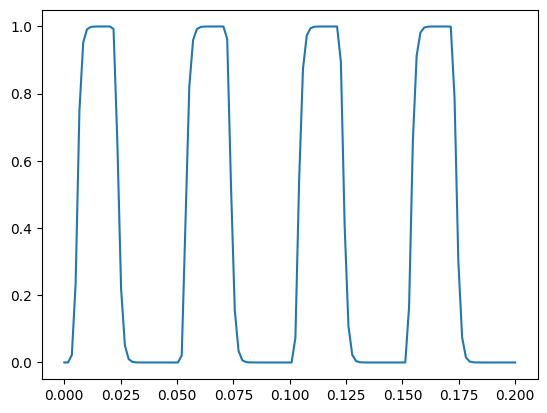

In [ ]:
plt.plot(res.tau, res.x[:, 0, 200])

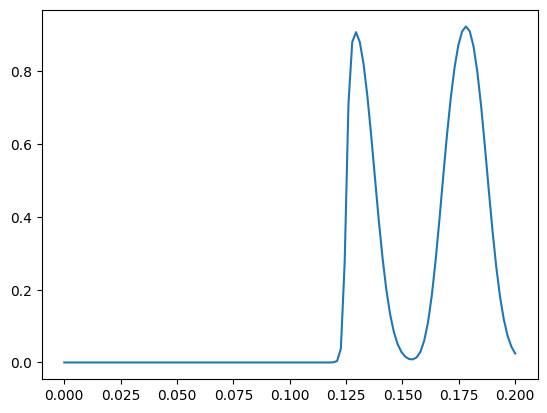

In [ ]:
plt.plot(res.tau, res.x[:, 0, 3200])

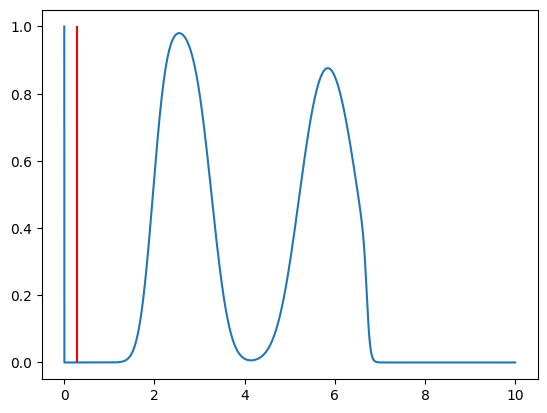

In [ ]:
from matplotlib import pyplot as plt
plt.plot(res.xi, res.x[119, 0])
plt.vlines(res.xi[200], 0, 1, color='red')

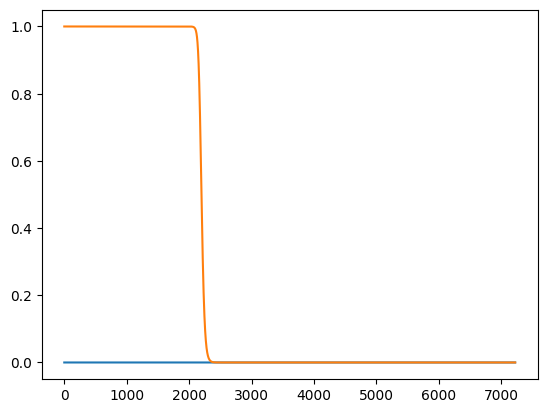

In [ ]:
plt.plot(res.theta[0])
plt.plot(res.theta[40])

# Analytical

In [ ]:
def peclet(u, L, D):
    """Eq. (11)."""
    return u * L / D


def damkoehler(R, L, D, v_th, beta0):
    """Eq. (12).  1/(2R) is S_v/4 for a tube."""
    return (1.0 / (2.0 * R)) * (L ** 2 / D) * v_th * beta0


def excess_number(s0, n0, R):
    """Eq. (13).  s0 is the area per site, i.e. 1/Gamma."""
    return s0 * n0 * R / 2.0


def plug_flow_coverage(xi, tau, Pe, Da, gamma):
    """Analytic plug-flow coverage, Eq. (24) of Yanguas-Gil, Libera & Elam,
    JVST A 39, 062404 (2021) / arXiv:2106.07132, in dimensionless form.

    The published form is

        Theta(z; t_d) = (exp(t_d/t_bar) - 1) / (exp(z/z_bar) + exp(t_d/t_bar) - 1)
        t_bar = 4 k_B T / (s_0 v_th b_0 p_0)                            (25)
        z_bar = (V/S) 4u / (v_th b_0)                                   (26)

    Substituting the groups of the 2012 paper (V/S = 1/S_v for any geometry):

        t/t_bar = gamma * Da * tau        z/z_bar = xi * Da / Pe

    so the plug-flow solution is the Pe -> infinity limit of Eqs. (9)-(10)
    at fixed Da/Pe, i.e. the same 1-D system with axial diffusion switched off.

    Two limits worth noting:
      * at xi = 0 this reduces to Theta = 1 - exp(-tau gamma Da), the
        well-mixed Langmuir result;
      * the half-coverage front sits at xi = (Pe/Da) ln(exp(gamma Da tau) - 1),
        i.e. it advances *linearly* in time, whereas the diffusion-limited
        (Pe = 0) front advances as sqrt(tau).

    Returns the CONSUMED fraction, matching ReactorProfile.growth_profile().
    """
    xi = np.asarray(xi, dtype=float)
    e_t = np.exp(gamma * Da * tau)
    return (e_t - 1.0) / (np.exp(xi * Da / Pe) + e_t - 1.0)


def plug_flow_scales(T, s0, v_th, beta0, p0, u, S_v):
    """The dimensional scales of Eqs. (25)-(26): (t_bar [s], z_bar [m])."""
    t_bar = 4.0 * kB * T / (s0 * v_th * beta0 * p0)
    z_bar = (1.0 / S_v) * 4.0 * u / (v_th * beta0)
    return t_bar, z_bar


def axial_velocity(flow_sccm, p_torr, T, R):
    """Eq. (14): u = (p0 T phi) / (p T0 pi R^2), phi in sccm."""
    p0, T0 = 101325.0, 273.15          # standard conditions for sccm
    phi = flow_sccm * 1e-6 / 60.0      # sccm -> m^3/s at STP
    p = p_torr * 133.322
    return p0 * T * phi / (p * T0 * np.pi * R ** 2)


In [ ]:
t_bar, z_bar = plug_flow_scales(T, s0, v_th, beta0, p0, u, S_v)
plug_flow_coverage(xi, tau, Pe=65, Da=1550, gamma=2.5)

# Modular

In [ ]:
class ReactorProfile:
    """Result of :func:`solve`.

    xi    : (n_xi,)          normalised axial position z/L
    tau   : (n_t,)           normalised time t D / L^2
    x     : (n_t, n_xi)      normalised precursor density n/n_0
    theta : (n_t, n_xi)      fraction of AVAILABLE sites (paper convention)
    """

    def __init__(self, xi, tau, x, theta):
        self.xi = xi
        self.tau = tau
        self.x = x
        self.theta = theta

# --------------------------------------------------------------------------
# dimensional helpers (Eqs. 11-15)
# --------------------------------------------------------------------------
def peclet(u, L, D):
    """Eq. (11)."""
    return u * L / D


def damkoehler(R, L, D, v_th, beta0):
    """Eq. (12).  1/(2R) is S_v/4 for a tube."""
    return (1.0 / (2.0 * R)) * (L ** 2 / D) * v_th * beta0


def excess_number(s0, n0, R):
    """Eq. (13).  s0 is the area per site, i.e. 1/Gamma."""
    return s0 * n0 * R / 2.0

def torr_to_pa(p_torr):
    return p_torr * 133.322

def axial_velocity(flow_sccm, p_torr, T, R):
    """Eq. (14): u = (p0 T phi) / (p T0 pi R^2), phi in sccm."""
    p0, T0 = 101325.0, 273.15          # standard conditions for sccm
    phi = flow_sccm * 1e-6 / 60.0      # sccm -> m^3/s at STP
    p = torr_to_pa(p_torr) #p_torr * 133.322
    return p0 * T * phi / (p * T0 * np.pi * R ** 2)

def adsorption_area(b_film=2.0, rho=3990.0, gpc=106e-12, M=101.96e-3):
    return M/(b_film * rho*gpc)

def particle_velocity(M, T):
    return np.sqrt(8*kB*T/(np.pi*M))

In [ ]:
import numpy as np
from scipy.constants import Boltzmann as kB
from scipy.constants import N_A

from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix

INCLUSIVE_THETA = True
if INCLUSIVE_THETA:
    th_exc = lambda th, n: th[1:n]
    x_exc = lambda x, n: x
else:
    th_exc = lambda th, n: th
    x_exc = lambda x, n: x[1:n]


class Reactant:
    def __init__(self, vth, M, beta, n0):
        self.vth = vth
        self.M = M
        self.beta = beta
        self.n0 = n0

    def diffusion_coefficient(self, M0, p, T):
        sigma, omega = 3.5, 0.5
        D = 3 / (8*np.sqrt(2*np.pi)) * (kB * T)**(3/2) * (1/self.M + 1/M0)**(1/2) / (p * (sigma * 1e-10)**2 * omega)
        self.D = D
        return self.D
    def damkoehler(self, R, L, D):
        self.Da = damkoehler(R, L, D, self.vth, self.beta)
        return self.Da
    def excess_number(self, s0, R):
        self.gamma = excess_number(s0, self.n0, R)
        return self.gamma

class Reactor_1D:
    def __init__(self, Pe=None, Da=None, gamma=None, D=None):
        self.Pe = {} if Pe is None else Pe
        self.Da = {} if Da is None else Da
        self.gamma = {} if gamma is None else gamma
        self.D = {} if D is None else D
        self.reactants = {}

    def set_reactor_parameters(self, T, L, R, V=None):
        self.T = T
        self.L = L
        self.R = R
        self.V = V if V is not None else np.pi * R ** 2 * L

    def set_sample_parameters(self, s0, S):
        self.s0 = s0
        self.S = S

    def set_carrier_parameters(self, flow_sccm, M0, p=None, p_torr=None):
        self.flow_sccm = flow_sccm
        self.p = p if p is not None else torr_to_pa(p_torr)
        self.M0 = M0
        self.u = axial_velocity(self.flow_sccm, self.p, self.T, self.R)
        #peclet(u, L, D)

    def set_reactant_parameters(self, id, vth, M, n0, beta):
        self.reactants[id] = Reactant(vth, M, beta, n0)
        #self.reactants[id].diffusion_coefficient(self.M0, self.p, self.T)
        #damkoehler(R, L, D, v_th, beta0)
        #excess_number(s0, n0, R)
        R_i = self.reactants[id]
        self.D[id] = R_i.diffusion_coefficient(self.M0, self.p, self.T)
        self.Da[id] = R_i.damkoehler(self.R, self.L, self.D[id])
        self.gamma[id] = R_i.excess_number(self.s0, self.R)
        self.Pe[id] = peclet(self.u, self.L, self.D[id])

    def recompute_reactant_parameters(self):
        for id in self.reactants:
            R_i = self.reactants[id]
            self.D[id] = R_i.diffusion_coefficient(self.M0, self.p, self.T)
            self.Da[id] = R_i.damkoehler(self.R, self.L, self.D[id])
            self.gamma[id] = R_i.excess_number(self.s0, self.R)
            self.Pe[id] = peclet(self.u, self.L, self.D[id])

class ReactorSetupProfile:

    def __init__(self, xi=None, tau=None, x=None, theta=None):
        self.xi = xi
        self.tau = tau
        self.theta = {} if theta is None else theta
        self.x = {} if x is None else x

    def construct_time_profile(self, tau_end, dz=None, n_out=None):
        if n_out is None:
            #dt = 0.2 * dz**2
            if dz is None:
                if self.dz is None:
                    dz = 0.1
                    print('No dz found or provided.')
                else:
                    dz = self.dz
            dt = (0.2 * dz**2)
            t_steps = tau_end // dt
            self.tau = dt * np.arange(0, int(t_steps) + 1)
        else:
            self.tau = np.linspace(0, tau_end, n_out)

    def construct_space_profile(self, xi_max, Pe, n_xi=None, min_xi=1000):
        # If multiple Pe values, use max Pe ?
        if n_xi is None:
            n_xi = max(min_xi, int(np.ceil(Pe * xi_max / 0.09)))
        n = int(n_xi)
        xi = np.linspace(0.0, xi_max, n + 1)
        d = xi[1] - xi[0]
        if Pe * d > 0.1:
            raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                            % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))
        self.xi = xi
        self.dz = d

    def initialize_theta(self, id, n=None, theta=None, initial_theta=0.0):
        if n is None:
            if self.xi is None:
                raise ValueError("xi not defined")
            else:
                n = len(self.xi)
        elements = n+1 if INCLUSIVE_THETA else n-1
        if theta is None:
            self.theta[id] = np.full(elements, float(initial_theta))
        else:
            if n is not None:
                assert len(theta) == (elements)
            self.theta[id] = theta

    def initialize_x(self, id, n=None, x=None, initial_x=0.0):
        if n is None:
            if self.xi is None:
                raise ValueError("xi not defined")
            else:
                n = len(self.xi)

        if x is None:
            self.x[id] = np.full(n - 1, float(initial_x))
        else:
            if n is not None:
                assert len(x) == (n - 1)
            self.x[id] = x

    def flat_input_array(self):
        items = []
        for RC in self.x:
            items.append(self.x[RC])
        items.append(self.theta[0])
        return np.concatenate(items)

class ALD_Reactor_Model:
    def __init__(self,
                 T=200+273, L=45*1e-2, R=2.5*1e-2,
                 s0=adsorption_area(), S=45*1e-2*2*np.pi*2.5*1e-2,
                 p_torr=1.0, flow_sccm=300, M0=28.0,
                 reactant_data={'TMA': {'M': 72.09,'n0_torr': 10e-3, 'beta': 0.01},
                                'H2O':{'M': 18.02,'n0_torr': 200e-3, 'beta': 0.01}},
                 xi_max=10, n_xi=int(np.ceil(10/0.002)), tau_end=0.2, tau_n=None,
                 inlet=None, outlet=None):
        #self.ids = ids
        self.reactor = Reactor_1D()
        self.reactor.set_reactor_parameters(T=T, L=L, R=R, V=None)
        self.reactor.set_sample_parameters(s0, S)
        self.reactor.set_carrier_parameters(p=torr_to_pa(p_torr), flow_sccm=flow_sccm,
                                            M0=M0 / N_A)

        self.Da = []
        self.Pe = []
        self.gamma = []

        max_Pe = 0
        for RC in reactant_data:
            r_data = reactant_data[RC]
            M = r_data['M'] / N_A
            n0 = torr_to_pa(r_data['n0_torr'])
            beta = r_data['beta']
            vth = particle_velocity(M, T)
            self.reactor.set_reactant_parameters(RC, vth, M, n0, beta)
            if self.reactor.Pe[RC] > max_Pe:
                max_Pe = self.reactor.Pe[RC]

            self.Da.append(self.reactor.Da[RC])
            self.Pe.append(self.reactor.Pe[RC])
            self.gamma.append(self.reactor.gamma[RC])

        self.Da = np.array(self.Da)[:, None]
        self.Pe = np.array(self.Pe)[:, None]
        self.gamma = np.array(self.gamma)[:, None]

        self.reactor.recompute_reactant_parameters()

        #return

        #Get reactor parameters
        self.setup = ReactorSetupProfile()
        self.setup.construct_space_profile(xi_max, max_Pe, n_xi=None, min_xi=1000)
        self.setup.construct_time_profile(tau_end=tau_end, dz=None, n_out=tau_n)

        #Make the profiles
        for RC in reactant_data:
            self.setup.initialize_x(RC, n=None, x=None, initial_x=0.0)

        self.setup.initialize_theta(0, n=None, theta=None, initial_theta=0.0)

        if inlet is None:
            self.inlet = lambda t: np.array([1.0, 0.0]).T
        else:
            self.inlet = inlet

        if outlet is None:
            self.outlet = lambda t: np.array([0.0, 0.0]).T
        else:
            self.outlet = outlet

    def run_model(self, outlet="dirichlet", epsilon=1.0, rtol=1e-7, atol=1e-10, method="BDF"):
    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
        Da = self.Da
        Pe = self.Pe
        gamma = self.gamma

        n = len(self.setup.xi)
        d = self.setup.dz
        nx = n - 1
        inv_d2 = 1.0 / d ** 2
        half_pe = Pe / (2.0 * d)
        tau_end = self.setup.tau[-1]
        inlet = self.inlet

        def rhs(t, y):
            #y = np.clip(y, 0.0, 1.0)
            xi_x1 = y[:nx]
            xi_x2 = y[nx:2*nx]
            th = y[2*nx:]
            #th = np.clip(th, 0.0, 1.0)

            x1_full = np.empty(n + 1)
            #x1_full[0] = inlet(t)
            x1_full[1:n] = xi_x1
            #x1_full[n] = x1_full[n - 1] if outlet == "noflux" else self.outlet[0,0]#0.0

            x2_full = np.empty(n + 1)
            #x2_full[0] = 0 #1.0 - inlet(t)
            x2_full[1:n] = xi_x2
            #x2_full[n] = x2_full[n - 1] if outlet == "noflux" else self.outlet[1,0]
            x_full = np.stack((x1_full, x2_full))
            x_full[:, n] = x_full[:, n - 1] if outlet == "noflux" else self.outlet(t)
            x_full[:, 0] = self.inlet(t)

            lap = (x_full[:, :-2] - 2.0 * x_full[:, 1:-1] + x_full[:, 2:]) * inv_d2
            adv = -half_pe * (x_full[:, 2:] - x_full[:, :-2])
            diff = -np.stack((Da[0] * (1-th_exc(th,n)), Da[1] * (th_exc(th,n))))

            dx = ((lap + adv + (diff * x_full[:, 1:n])) / epsilon)
            dth = gamma[0] * Da[0] * (1-th) * x_exc(x_full[0], n) - \
                  gamma[1] * Da[1] * (th) * x_exc(x_full[1], n)

            res = np.concatenate((dx.ravel(), dth))
            #print(len(res), len(xi_x1), len(xi_x2), len(th))
            #print(dx.shape, lap.shape, adv.shape, diff.shape, x_full.shape)
            return res #np.concatenate((dx.ravel(), dth))

        dn_th = 1 if INCLUSIVE_THETA else -1
        boo_th = 1 if INCLUSIVE_THETA else 0
        jac_len = 2*nx + n + dn_th
        jac = lil_matrix((jac_len, jac_len), dtype=int)
        r = np.arange(nx)

        for c in range(2):
            jac[c*nx + r, c*nx + r] = 1
            jac[c*nx + r[:-1], c*nx + r[:-1] + 1] = 1
            jac[c*nx + r[1:], c*nx + r[1:] - 1] = 1

            jac[c*nx + r, 2*nx + boo_th + r] = 1              # x_i  <- theta_i
            jac[2*nx + boo_th + r, c*nx + r] = 1              # theta_i <- x_i
            if outlet == "noflux":
                jac[2*nx + n - 1 + dn_th, c*nx + nx - 1] = 1

        rt = np.arange(n + dn_th)
        jac[2*nx + rt, 2*nx + rt] = 1

        #y0 = np.concatenate((prof(x_init, 0.0)[1:n], prof(x_init, 0.0)[1:n], prof(theta_init, 0.0)))
        y0 = self.setup.flat_input_array() #np.concatenate(())
        #print(jac_len, len(y0))
        t_eval = self.setup.tau #np.linspace(0.0, tau_end, n_out)
        sol = solve_ivp(rhs, (0.0, tau_end), y0, method=method, t_eval=t_eval,
                        jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)

        if not sol.success:
            raise RuntimeError("integration failed: %s" % sol.message)

        x = np.empty((sol.t.size, 2, n + 1))
        x[:, :, 0] = [inlet(t) for t in sol.t]
        #x[:, 0, 0] = [inlet(t) for t in sol.t]
        #x[:, 1, 0] = [1-inlet(t) for t in sol.t]
        x[:, 0, 1:n] = sol.y[:nx].T
        x[:, 1, 1:n] = sol.y[nx:2*nx].T
        x[:, :, n] = x[:, :, n - 1] if outlet == "noflux" else 0.0
        theta = sol.y[2*nx:].T #np.clip(sol.y[2*nx:].T, 0.0, 1.0)
        return ReactorProfile(self.setup.xi, sol.t, x, theta)


## Run

In [ ]:

def custom_inlet(t):
    if t < 0.2:
        return np.array([1.0, 0.0]).T
    elif t < 10:
        return np.array([0.0, 0.0]).T
    else:
        return np.array([0.0, 1.0]).T

#test_model = ALD_Reactor_Model(xi_max=5.0, tau_end=0.4, inlet=custom_inlet)
#test_model = ALD_Reactor_Model(xi_max=5.0, tau_end=0.4, inlet=custom_inlet)

In [ ]:

test_model = ALD_Reactor_Model(T=100+273, L=64*1e-2, R=1.75*1e-2,
                            s0=adsorption_area(), S=64*1e-2*2*np.pi*1.75*1e-2,
                            p_torr=1.0, flow_sccm=120, M0=28.0, inlet=custom_inlet)

In [ ]:
# su = ALD_Reactor_Model(xi_max=1.0, tau_end=0.2).setup
# su.xi.shape, su.tau.shape
res = test_model.run_model()

[[0.050383 0.029803 0.527975 1.      ]]


Text(0, 0.5, 'Inlet Concentration n/$n_0$')

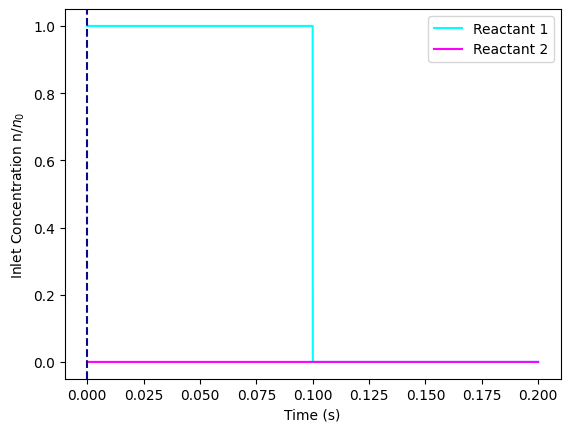

In [ ]:
from matplotlib import pyplot as plt
import numpy as np

ccnt = res.tau.shape[0]//10000
cmap_spaced = plt.get_cmap('plasma', ccnt)
print(cmap_spaced(np.linspace(0, 1, ccnt)))

accum = []
for t in res.tau:
    ns = custom_inlet(t)
    accum.append(ns)
accum = np.array(accum)
#plt.scatter(res.tau, accum[:, 0], c= cmap_spaced(np.linspace(0,1,len(accum))), cmap='plasma', marker='X')
#plt.scatter(res.tau, accum[:, 1], c= cmap_spaced(np.linspace(0,1,len(accum))), cmap='plasma', marker='s')
plt.plot(res.tau, accum[:, 0], color='cyan', label='Reactant 1')
plt.plot(res.tau, accum[:, 1], color='magenta', label='Reactant 2')

for v in np.linspace(0, 1, ccnt):
    plt.axvline(v*0.4, color=cmap_spaced(v), linestyle='--')

plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('Inlet Concentration n/$n_0$')

In [ ]:
res.x.shape

(10000, 2, 1002)

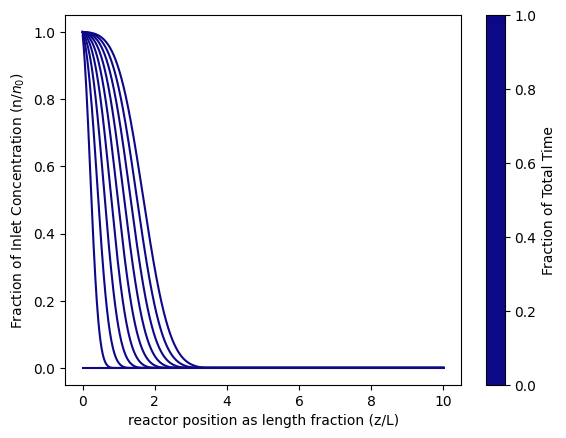

In [ ]:
#test_model.reactor.reactants['TMA'].vth
from matplotlib import cm
import matplotlib.pyplot as plt
xpos = res.xi
for i in range(0, res.x.shape[0], 1000):
    plt.plot(xpos, res.x[i,0,1:], color=cmap_spaced(i/res.tau.shape[0]))

plt.xlabel('reactor position as length fraction (z/L)')
plt.ylabel('Fraction of Inlet Concentration (n/$n_0$)')
mappable = cm.ScalarMappable(cmap=cmap_spaced)
plt.gcf().colorbar(mappable, ax=plt.gca(), label='Fraction of Total Time')

# Generalization

In [ ]:
# --------------------------------------------------------------------------
# dimensional helpers (Eqs. 11-15)
# --------------------------------------------------------------------------
def peclet(u, L, D):
    """Eq. (11)."""
    return u * L / D


def damkoehler(R, L, D, v_th, beta0):
    """Eq. (12).  1/(2R) is S_v/4 for a tube."""
    return (1.0 / (2.0 * R)) * (L ** 2 / D) * v_th * beta0


def excess_number(s0, n0, R):
    """Eq. (13).  s0 is the area per site, i.e. 1/Gamma."""
    return s0 * n0 * R / 2.0

def torr_to_pa(p_torr):
    return p_torr * 133.322

def axial_velocity(flow_sccm, p_torr, T, R):
    """Eq. (14): u = (p0 T phi) / (p T0 pi R^2), phi in sccm."""
    p0, T0 = 101325.0, 273.15          # standard conditions for sccm
    phi = flow_sccm * 1e-6 / 60.0      # sccm -> m^3/s at STP
    p = torr_to_pa(p_torr) #p_torr * 133.322
    return p0 * T * phi / (p * T0 * np.pi * R ** 2)

def adsorption_area(b_film=2.0, rho=3990.0, gpc=106e-12, M=101.96e-3):
    return M/(b_film * rho*gpc)

def particle_velocity(M, T):
    return np.sqrt(8*kB*T/(np.pi*M))

In [ ]:
import numpy as np
from scipy.constants import Boltzmann as kB
from scipy.constants import N_A

from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix

INCLUSIVE_THETA = True
if INCLUSIVE_THETA:
    th_exc = lambda th, n: th[1:n]
    x_exc = lambda x, n: x
else:
    th_exc = lambda th, n: th
    x_exc = lambda x, n: x[1:n]


class Reactant:
    def __init__(self, vth, M):
        self.vth = vth
        self.M = M
        #self.beta = beta
        #self.n0 = n0

    def diffusion_coefficient(self, M0, p, T):
        sigma, omega = 3.5, 0.5
        D = 3 / (8*np.sqrt(2*np.pi)) * (kB * T)**(3/2) * (1/self.M + 1/M0)**(1/2) / (p * (sigma * 1e-10)**2 * omega)
        self.D = D
        return self.D
    # def damkoehler(self, D):
    #     Da = 1/4 * self.vth * D
    #     return self.Da
    # def excess_number(self, s0):
    #     self.gamma = s0 * n0
    #     return self.gamma

class Reactor_1D:
    def __init__(self, Pe=None, D=None):
        #self.Pe = {} if Pe is None else Pe
        #self.Da = {} if Da is None else Da
        #self.gamma = {} if gamma is None else gamma

        self.x_rhs = {} #if Da is None else Da
        self.th_rhs = {} #if gamma is None else gamma

        self.D = {} if D is None else D
        self.reactants = {}

    def set_reactor_parameters(self, T, L, R, V=None):
        self.T = T
        self.L = L
        self.R = R
        self.V = V if V is not None else np.pi * R ** 2 * L

    def set_sample_parameters(self, s0, S):
        self.s0 = s0
        self.S = S

    def set_carrier_parameters(self, flow_sccm, M0, p=None, p_torr=None):
        self.flow_sccm = flow_sccm
        self.p = p if p is not None else torr_to_pa(p_torr)
        self.M0 = M0
        self.u = axial_velocity(self.flow_sccm, self.p, self.T, self.R)
        #peclet(u, L, D)

    def set_reactant_parameters(self, id, vth, M):
        self.reactants[id] = Reactant(vth, M)
        #self.reactants[id].diffusion_coefficient(self.M0, self.p, self.T)
        #damkoehler(R, L, D, v_th, beta0)
        #excess_number(s0, n0, R)
        R_i = self.reactants[id]
        self.D[id] = R_i.diffusion_coefficient(self.M0, self.p, self.T)
        #self.Da[id] = R_i.damkoehler(self.D[id])
        #self.gamma[id] = R_i.excess_number(self.s0, self.R)
        #self.Pe[id] = peclet(self.u, self.L, self.D[id])
        self.x_rhs[id] = (R_i.vth)/(4)
        self.th_rhs[id] = (self.s0*R_i.vth)/4
    # def recompute_reactant_parameters(self):
    #     for id in self.reactants:
    #         R_i = self.reactants[id]
    #         self.D[id] = R_i.diffusion_coefficient(self.M0, self.p, self.T)
    #         self.Da[id] = R_i.damkoehler(self.R, self.L, self.D[id])
    #         self.gamma[id] = R_i.excess_number(self.s0, self.R)
    #         self.Pe[id] = peclet(self.u, self.L, self.D[id])

class ReactorSetupProfile:

    def __init__(self, z=None, tau=None, x=None, theta=None):
        self.z = z
        self.tau = tau
        self.theta = {} if theta is None else theta
        self.x = {} if x is None else x

    def construct_time_profile(self, tau_end, D, dz=None, n_out=None):
        if n_out is None:
            #dt = 0.2 * dz**2
            if dz is None:
                if self.dz is None:
                    dz = 0.1
                    print('No dz found or provided.')
                else:
                    dz = self.dz
            dt = (0.2 * dz**2)/D
            t_steps = tau_end // dt
            self.dt = dt
            self.tau = dt * np.arange(0, int(t_steps) + 1)
        else:
            self.tau = np.linspace(0, tau_end, n_out)
            #self.dt = self.tau[1] - self.tau[0]

    def construct_space_profile(self, z_max, u_D=None, n_z=None, min_z=100):
        #where u_D is u/D
        # If multiple Pe values, use max Pe ?
        if n_z is None:
            #n_xi = max(min_xi, int(np.ceil(Pe * xi_max / 0.09)))
            d = 0.1/u_D
            n = int(np.ceil(z_max/d))
        else:
            n = int(n_z)
        z = np.linspace(0.0, z_max, n + 1)
        d = z[1] - z[0]
        # if Pe * d > 0.1:
        #     raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
        #                     % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))
        self.z = z
        self.dz = d

    def initialize_theta(self, id, n=None, theta=None, initial_theta=0.0):
        if n is None:
            if self.z is None:
                raise ValueError("z not defined")
            else:
                n = len(self.z)
        elements = n+1 if INCLUSIVE_THETA else n-1
        if theta is None:
            self.theta[id] = np.full(elements, float(initial_theta))
        else:
            if n is not None:
                assert len(theta) == (elements)
            self.theta[id] = theta

    def initialize_x(self, id, n=None, x=None, initial_x=0.0):
        if n is None:
            if self.z is None:
                raise ValueError("xi not defined")
            else:
                n = len(self.z)

        if x is None:
            self.x[id] = np.full(n - 1, float(initial_x))
        else:
            if n is not None:
                assert len(x) == (n - 1)
            self.x[id] = x

    def flat_input_array(self):
        items = []
        for RC in self.x:
            items.append(self.x[RC])
        items.append(self.theta[0])
        return np.concatenate(items)



class ALD_Reactor_Model:
    def __init__(self,
                 T=200+273, L=45*1e-2, R=2.5*1e-2,
                 s0=adsorption_area(), S=45*1e-2*2*np.pi*2.5*1e-2, V=None,
                 p_torr=1.0, flow_sccm=300, M0=28.0,
                 reactant_data={'TMA': {'M': 72.09},
                                'H2O':{'M': 18.02}},
                 z_max=10*45e-2, n_z=None, tau_end=0.2, tau_n=None,
                 inlet=None, outlet=None):
        #self.ids = ids
        self.reactor = Reactor_1D()
        self.reactor.set_reactor_parameters(T=T, L=L, R=R, V=V)
        self.reactor.set_sample_parameters(s0, S)
        self.reactor.set_carrier_parameters(p=torr_to_pa(p_torr), flow_sccm=flow_sccm,
                                            M0=M0 / N_A)

        self.Ds = []
        self.x_rhs = []
        self.th_rhs = []


        #max_Pe = 0
        for RC in reactant_data:
            r_data = reactant_data[RC]
            M = r_data['M'] / N_A
            #n0 = torr_to_pa(r_data['n0_torr'])
            #beta = r_data['beta']
            vth = particle_velocity(M, T)
            self.reactor.set_reactant_parameters(RC, vth, M)
            # if self.reactor.Pe[RC] > max_Pe:
            #     max_Pe = self.reactor.u * self.reactor.L / self.reactor.D
                #self.reactor.Pe[RC]

            self.x_rhs.append(self.reactor.x_rhs[RC])
            self.th_rhs.append(self.reactor.th_rhs[RC])
            self.Ds.append(self.reactor.D[RC])

        self.x_rhs = np.array(self.x_rhs)[:, None]
        self.th_rhs = np.array(self.th_rhs)[:, None]
        self.Ds = np.array(self.Ds)[:, None]

        #Get reactor profiles
        # Spatial profile xi is normalized by L, but remember to multiply by L when displaying.
        # Cases where dz is used are scaled by L to account for us not using the 'normalized' coefficients
        self.setup = ReactorSetupProfile()
        self.setup.construct_space_profile(z_max, u_D = np.max(self.reactor.u/self.Ds), n_z=n_z, min_z=0)
        self.setup.construct_time_profile(tau_end=tau_end, D=np.max(self.Ds), dz=None, n_out=tau_n)

        #Make the profiles
        for RC in reactant_data:
            self.setup.initialize_x(RC, n=None, x=None, initial_x=0.0)

        self.setup.initialize_theta(0, n=None, theta=None, initial_theta=0.0)

        if inlet is None:
            self.inlet = lambda t: np.array([1.0, 0.0]).T
        else:
            self.inlet = inlet

        if outlet is None:
            self.outlet = lambda t: np.array([0.0, 0.0]).T
        else:
            self.outlet = outlet

        self.reset_internal_state()

    def reset_internal_state(self):
        self.y0 = self.setup.flat_input_array()
        self.old_inlet = np.zeros((2, 1), dtype='float')
        self.old_t = 0.0

    def run_model(self, outlet_type="dirichlet", epsilon=1.0, rtol=1e-7, atol=1e-10, method="BDF", betas = [0.001, 0.001],
                  perturbation = lambda x: x, t_offset=0, t_r = 0.22):
    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n

        n = len(self.setup.z)
        d = self.setup.dz # * self.reactor.L
        nx = n - 1
        #inv_d2 = 1.0 / d ** 2

        co_adv = -self.reactor.u / (2.0 * d)
        co_lap = self.Ds / (d ** 2)

        tau_end = self.setup.tau[-1]
        inlet = self.inlet
        outlet= self.outlet
        #dt = self.setup.tau[1] - self.setup.tau[0]

        def rhs(t, y):
            #y = np.clip(y, 0.0, 1.0)
            xi_x1 = y[:nx]
            xi_x2 = y[nx:2*nx]
            th = y[2*nx:]
            #th = np.clip(th, 0.0, 1.0)

            x1_full = np.empty(n + 1)
            #x1_full[0] = inlet(t)
            x1_full[1:n] = xi_x1
            #x1_full[n] = x1_full[n - 1] if outlet == "noflux" else self.outlet[0,0]#0.0

            x2_full = np.empty(n + 1)
            #x2_full[0] = 0 #1.0 - inlet(t)
            x2_full[1:n] = xi_x2

            # if (np.sum(x1_full[1:n])/(n-1) < 0.01) and (x1_full[1:n].max() < 0.1):
            #     x1_full[1:n] = 0.0
            # if (np.sum(x2_full[1:n])/(n-1) < 0.01) and (x2_full[1:n].max() < 0.1):
            #     x2_full[1:n] = 0.0
            # if (np.sum(th)/(th.shape[0]) < 0.01) and (th.min() < 0.01):
            #     th[:] = 0.0

            #x2_full[n] = x2_full[n - 1] if outlet == "noflux" else self.outlet[1,0]
            x_full = np.stack((x1_full, x2_full))


            I0, O0 = inlet(t+t_offset), outlet(t+t_offset)

            for i in range(len(x_full)):
                OI = self.old_inlet[i]
                if I0[i] is None:
                    #x_full[i, 0] = x_full[i, 1] + dt * (x_full[i, 1] - x_full[i, 2])
                    #x_full[i, 0] = OI + dt * (3*(x_full[i, 1] - x_full[i, 2]) + x_full[i, 3])
                    #x_full[i, 0] = OI + dt * ((2.5*x_full[i, 1] - 3*x_full[i, 2]) + 0.5*x_full[i, 3])
                    #x_full[i, 0] = x_full[i, 1]
                    #x_full[i, 0] = (self.old_inlet[i]+(co_lap[i]+co_adv)*x_full[i, 1])/(1+co_lap[i]+co_adv)
                    #x_full[i, 0] = OI + dt * (co_lap[i] * 2 * (x_full[i, 1] - OI) + co_adv * (x_full[i, 1] - OI))
                    #x_full[i, 0] = OI + dt * co_adv * (x_full[i, 1] - OI) #dt * (co_lap[i] * 2 * (x_full[i, 1] - OI))
                    x_full[i, 0] = OI * np.exp(-np.abs(dt/t_r)) #+ dt*0.5 * (co_lap[i] * 2 * (x_full[i, 1] - OI))
                else:
                    #x_full[i, 0] = I0[i]-(dt/0.1)*(I0[i] - OI)
                    x_full[i, 0] = I0[i] #inlet(t+t_offset)

                x_full[i, n] = x_full[i, n - 1] if outlet_type == "noflux" else O0[i]
            #x_full[:, n] += perturbation(t, x_full) #'restore' gas concentration lost to the 'perturbation'

            x_full = perturbation(x_full)
            #x_full += perturbation(t, x_full) #'restore' gas concentration lost to the 'perturbation'
            co_diff = -np.stack((self.x_rhs[0] * betas[0] * (1-th_exc(th,n)),
                              self.x_rhs[1] * betas[1] * (th_exc(th,n))))

            # print("Has NaNs:", np.isnan(x_full).any())
            # print("Has Infs:", np.isinf(x_full).any())
            # print(x_full[0,:3])

            lap = co_lap * (x_full[:, :-2] - 2.0 * x_full[:, 1:-1] + x_full[:, 2:])
            adv = co_adv * (x_full[:, 2:] - x_full[:, :-2])
            diff = co_diff * x_full[:, 1:n]

            dx = (lap + adv + diff)/epsilon

            #dx = ((self.Ds * lap + adv + diff * x_full[:, 1:n]) / epsilon)

            #dx = ((self.Ds * lap + adv) / epsilon)

            dth = self.th_rhs[0] * betas[0] * (1-th) * x_exc(x_full[0], n) - \
                  self.th_rhs[1] * betas[1] * (th) * x_exc(x_full[1], n)

            res = np.concatenate((dx.ravel(), dth))
            #print(len(res), len(xi_x1), len(xi_x2), len(th))
            #print(dx.shape, lap.shape, adv.shape, diff.shape, x_full.shape)

            self.old_inlet = x_full[:, 0]

            return res #np.concatenate((dx.ravel(), dth))

        dn_th = 1 if INCLUSIVE_THETA else -1
        boo_th = 1 if INCLUSIVE_THETA else 0
        jac_len = 2*nx + n + dn_th
        jac = lil_matrix((jac_len, jac_len), dtype=int)
        r = np.arange(nx)

        for c in range(2):
            jac[c*nx + r, c*nx + r] = 1
            jac[c*nx + r[:-1], c*nx + r[:-1] + 1] = 1
            jac[c*nx + r[1:], c*nx + r[1:] - 1] = 1

            jac[c*nx + r, 2*nx + boo_th + r] = 1              # x_i  <- theta_i
            jac[2*nx + boo_th + r, c*nx + r] = 1              # theta_i <- x_i
            if outlet_type == "noflux":
                jac[2*nx + n - 1 + dn_th, c*nx + nx - 1] = 1

        rt = np.arange(n + dn_th)
        jac[2*nx + rt, 2*nx + rt] = 1

        #y0 = np.concatenate((prof(x_init, 0.0)[1:n], prof(x_init, 0.0)[1:n], prof(theta_init, 0.0)))
        #y0 = self.setup.flat_input_array() #np.concatenate(())
        #print(jac_len, len(y0))
        t_eval = self.setup.tau #np.linspace(0.0, tau_end, n_out)
        sol = solve_ivp(rhs, (0.0, tau_end), self.y0, method=method, t_eval=t_eval,
                        jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)

        if not sol.success:
            raise RuntimeError("integration failed: %s" % sol.message)

        #self.y0 = sol.y[:, -1]
        x = np.empty((sol.t.size, 2, n + 1))
        x[:, :, 0] = [inlet(t+t_offset) for t in sol.t]
        #x[:, 0, 0] = [inlet(t) for t in sol.t]
        #x[:, 1, 0] = [1-inlet(t) for t in sol.t]
        x[:, 0, 1:n] = sol.y[:nx].T
        x[:, 1, 1:n] = sol.y[nx:2*nx].T
        theta = sol.y[2*nx:].T

        if (np.sum(x[-1, 0, 1:n])/(n-2) < 0.01) and (x[-1, 0, 1:n].max() < 0.01):
            x[-1, 0, 1:n] = 0.0
        if (np.sum(x[-1, 1, 1:n])/(n-2) < 0.2) and (x[-1, 1, 1:n].max() < 0.2):
            x[-1, 1, 1:n] = 0.0
        if (np.sum(theta[-1])/(theta.shape[1]) < 0.01) and (theta[-1].min() < 0.01):
            theta[-1, :] = 0.0

        self.y0 = np.concatenate((x[-1, :, 1:n].ravel(), theta[-1].ravel()))
        #np.concatenate((x[:, 0, 1:n].ravel(), x[:, 1, 1:n].ravel(), theta.ravel()), axis=0)

        x[:, :, n] = x[:, :, n - 1] if outlet == "noflux" else [outlet(t+t_offset) for t in sol.t]

         #np.clip(sol.y[2*nx:].T, 0.0, 1.0)
        #return ReactorProfile(self.setup.xi*self.reactor.L, sol.t, x, theta)
        return x[-1], theta[-1]


In [ ]:
class Sample_Model:
    def __init__(self, xpos, t_ratio, S, V,
                 vths=None, masses=None):
        self.S = S
        self.V = V
        self.t_ratio = t_ratio #time/mass, converts mass change into a time change
        #self.rho = rho #mass per formula unit
        self.xpos = xpos
        #self.dt = dt
        #self.betas = betas
        #self.s0 = s0 #area per formula unit
        self.delta_m = 0
        #self.reactants = reactants
        # coverage_conv = []
        # bt_conv = []
        self.vths = vths
        self.masses = masses
        self.set_mass_change(0)
        # for rc in self.reactants:
        #     RC = self.reactants[rc]
        #     dN = 1/RC.M
    #         dS = dN * self.s0
    #         dth = dS / self.S
    #         coverage_conv.append(dth)
    #         bt_conv.append(1/4 * RC.vth)

    #     self.coverage_conv = np.array(coverage_conv)[:, None]
    #     self.bt_conv = np.array(bt_conv)[:, None]

    def set_mass_change(self, mass_change):
        self.delta_m = mass_change * self.t_ratio
        self.delta_c = self.delta_m / (self.masses * self.V)
        #self.delta_theta = self.get_coverage_change(mass_change)

    # def get_coverage_change(mass_change):
    #     # delta_coverage = []
    #     # for rc in self.reactants:
    #     #     RC = self.reactants[rc]
    #     #     dN = mass_change/RC.M
    #     #     dS = dN * RC.s0
    #     #     dth = dS / self.S
    #     #     delta_coverage.append(dth)
    #     return mass_change * self.coverage_conv

    # def get_beta_theta(cx, coverage_change):
    #     #Use integrated form of the coverage over time curve to match the coverage change at concentration x, solve for beta*(1-th)
    #     #Don't use the integrated form, linearity of the differential equation form is easier to use
    #     #return coverage_change / (cx * self.bt_conv * self.s0)
    #     return coverage_change / (self.s0)

    # def get_conc_change(cx, betatheta):
    #     #S/V * ...
    #     #return self.S/self.V * betatheta * cx * self.bt_conv
    #     return self.S/self.V * betatheta# * cx * self.bt_conv

    #self.S/self.V /(self.s0) /self.S * self.s0/RC.M * masschange
    #masschange/(V * M)
    def update_beta_theta(self, cx):
        divisor = cx * self.vths/4 * self.S * self.masses
        return self.delta_m / divisor

    def get_perturbation(self, x_full):
        #Use Mass Change to get volume to get surface fraction
        #Use surface fraction change and concentration to estimate beta
        #Get concentration change
        #Make it 'positive', assuming we are returning the perturbation amount if the true outlet is losing this amount
        # cx = np.mean(x_full[:, self.xpos], axis=1)
        # beta_theta = self.get_beta_theta(cx, self.delta_theta)
        # conc_change = self.get_conc_change(cx, beta_theta)
        conc_change = - self.delta_c * (x_full.shape[1]/len(self.xpos))
        self.betatheta = self.update_beta_theta(np.mean(x_full[:, self.xpos], axis=1))

        x_full[:, self.xpos] += conc_change
        return x_full

        #return conc_change

In [ ]:
# @title
# def custom_inlet(t):
#     if t < 0.1:
#         return np.array([1.0, 0.0]).T
#     elif t < 0.3:
#         return np.array([0.0, 0.0]).T
#     else:
#         return np.array([0.0, 1.0]).T

# def custom_outlet(t):
#     if t < 0.1:
#         return np.array([1.0, 0.0]).T
#     elif t < 0.3:
#         return np.array([0.0, 0.0]).T
#     else:
#         return np.array([0.0, 1.0]).T

# test_model = ALD_Reactor_Model(xi_max=5.0, tau_end=0.4, inlet=custom_inlet)

# seo_model = ALD_Reactor_Model(T=100+273, L=64*1e-2, R=1.75*1e-2,
#                             s0=adsorption_area(), S=64*1e-2*2*np.pi*1.75*1e-2,
#                             p_torr=1.0, flow_sccm=120, M0=28.0,
#                             reactant_data={'TMA': {'M': 72.09,'n0_torr': 10e-3, 'beta': 0.01},
#                                             'H2O':{'M': 18.02,'n0_torr': 200e-3, 'beta': 0.01}},
#                             xi_max=1.0, n_xi=int(np.ceil(1.0/0.002)), tau_end=0.2, tau_n=None,
#                             inlet=custom_inlet, outlet=custom_outlet)
# #
# res = test_model.run_model()
#xpos from 31/64 to 36/64


In [ ]:
tma_n0 = torr_to_pa(10e-3)
h2o_n0 = torr_to_pa(200e-3)

OFF_STATE = 0

class ModelStepper:
    def __init__(self, model=None, t_step=0.02):
        if model is None:
            self.model_init(t_step=t_step)
        else:
            self.model = model

        self.t_step = t_step
        self.sample_model_init()

        self.set_recipe([{'t': 0.3, 'p': [tma_n0, OFF_STATE]},
                        {'t': 60, 'p': [OFF_STATE, OFF_STATE]},
                        {'t': 1.0, 'p': [OFF_STATE, h2o_n0]},
                        {'t': 60, 'p': [OFF_STATE, OFF_STATE]}],
                        t_step)

    def set_recipe(self, recipe, t_step, pad=10, t_r=0.1):
        #Assumes the padding offstate pressure is also the case for the last state pressure
        self.recipe = recipe
        self.cycle_time = np.sum([stage['t'] for stage in recipe])

        conc = np.zeros((round((self.cycle_time+pad) / t_step)+1, 2), dtype='float')
        cstate = np.array([0, 0])[...,None].T
        ct = pad
        edge_length = round(t_r/t_step)
        interp = np.linspace(0, 1, edge_length*2+1)[...,None]

        for stage in recipe:
            #conc.append(stage['p']*int(stage['t']//t_step+1))
            center_point = round(ct/t_step)
            stage_p = np.array(stage['p'])[...,None].T
            print(cstate, stage_p)
            conc[center_point-edge_length:center_point+edge_length+1, :] = interp*stage_p + (1-interp)*cstate
            conc[center_point+edge_length+1:,:] = stage_p
            cstate = stage_p
            ct += stage['t']

        #Clamp off relevant conc section
        start_index = np.argmax(np.sum(conc != 0, axis=1)!=0)
        self.conc = conc[start_index-1: start_index + round(self.cycle_time/t_step), :]

    def model_init(self, t_step, z_max=64*1e-2, L = 64*1e-2, R = 1.75*1e-2,
                   n_z = 501, tau_n = 2):

        self.model = ALD_Reactor_Model(T=100+273, L=L, R=R,
                                    s0=adsorption_area(), S=L*2*np.pi*R,
                                    p_torr=1.0, flow_sccm=120, M0=28.0,
                                    reactant_data={'TMA': {'M': 72.09},
                                                    'H2O':{'M': 18.02}},
                                    z_max=z_max, n_z=n_z,
                                    tau_end=t_step, tau_n=tau_n,
                                    inlet=self.I_by_time, outlet=None)
        #flow_sccm=120

    def sample_model_init(self, position_range = (31*1e-2, 35*1e-2), Asurf = (0.8e-4)*3, t_mass=0.1):
        #dt = self.model.setup.dt
        z = self.model.setup.z #* self.model.reactor.L
        zpos = np.where(np.logical_and(z>=position_range[0], z<=position_range[1]))[0]
        vths = []
        masses = []
        for rc in self.model.reactor.reactants:
            RC = self.model.reactor.reactants[rc]
            masses.append(RC.M)
            vths.append(RC.vth)

        vths = np.array(vths)[:, None]
        masses = np.array(masses)[:, None]

        self.sample_model = Sample_Model(zpos, t_ratio=self.t_step/t_mass, S=Asurf,
                                         V=self.model.reactor.V,
                                         vths=vths, masses = masses)

    def I_by_time(self, t):
        t_ = t % self.cycle_time

        return self.conc[round(t_/self.t_step)]
        # total_time = 0
        # for stage in self.recipe:
        #     if t_ <= total_time + stage['t']:
        #         return stage['p'] #np.array(stage['p'])
        #     total_time += stage['t']
        #print('time exceeds cycle time')

    def O_by_time(self, t):
        t_ = t % self.cycle_time
        total_time = 0
        for stage in self.recipe:
            if t_ <= total_time + stage['t']:
                return np.array(stage['p']) * 0.8
            total_time += stage['t']
        #print('time exceeds cycle time')

    def run_model(self, time, log_freq=10, use_perturbation=False):
        x_log = []
        theta_log = []
        betatheta_log = []
        tau_log = []
        tau_end = self.t_step #self.model.setup.tau[-1]
        perturbation = self.sample_model.get_perturbation if use_perturbation else lambda x: x

        for i in range(int(time//tau_end)+1):
            t = i * tau_end

            x, theta = self.model.run_model(betas = [0.001, 0.001],
                                            perturbation = perturbation,
                                            t_offset=t, outlet_type='noflux', #outlet_type='derichlet',
                                            method = 'RK45')
            if i % log_freq == 0:
                x_log.append(x)
                theta_log.append(theta)
                tau_log.append(t)
                if use_perturbation:
                    betatheta_log.append(self.sample_model.betatheta)
        if use_perturbation:
            return np.array(x_log), np.array(theta_log), np.array(betatheta_log), np.array(tau_log)
        else:
            return np.array(x_log), np.array(theta_log), np.array(tau_log)

In [ ]:
#test it out...?
mstep = ModelStepper()

[[0 0]] [[1.33322 0.     ]]
[[1.33322 0.     ]] [[0 0]]
[[0 0]] [[ 0.     26.6644]]
[[ 0.     26.6644]] [[0 0]]


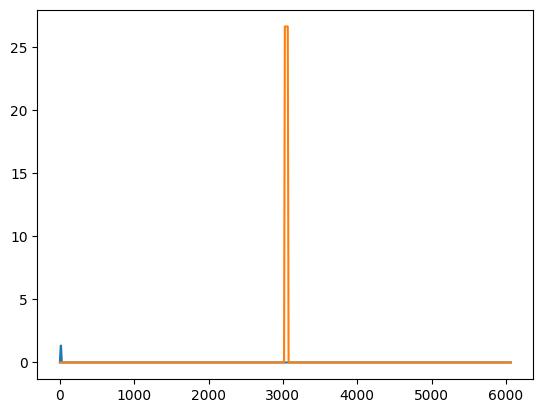

In [ ]:
import matplotlib.pyplot as plt
# #mstep.model.setup.construct_time_profile(tau_end=0.2, D=np.max(mstep.model.Ds), dz=None, n_out=10)
# #mstep.setup.construct_space_profile(xi_max, u_D = np.max(mstep.reactor.u/mstep.Ds), n_xi=n_xi, min_xi=0)
# #mstep.setup.construct_time_profile(tau_end=tau_end, D=np.max(mstep.Ds), dz=None, n_out=None)
# #mstep.model.setup.dz
# #np.max(mstep.model.reactor.u/mstep.model.Ds)
# # d = 0.1/u_D
# # n = int(np.ceil(xi_max/d))
# int(np.ceil(10/(0.1/13.83)))
#mstep.model.reactor.V
#mstep.model.setup.tau
plt.plot(mstep.conc[:])
#plt.plot(mstep.conc[5000:7000])
#plt.plot(mstep.conc)

In [ ]:
res = mstep.run_model(150, use_perturbation=False)

In [ ]:
#res[-1]
#[mstep.I_by_time(t)[0] for t in res[-1]]
#plt.plot(res[-1][0:30], i1_out[0:30])
#plt.plot(res[-1][6000:6100], i1_out[6000:6100])

[]

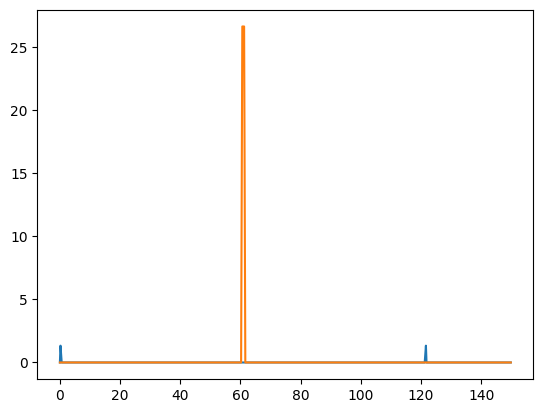

In [ ]:
i1_out = [mstep.I_by_time(t)[0] if mstep.I_by_time(t)[0] != None else 0 for t in res[-1]]
i2_out = [mstep.I_by_time(t)[1] if mstep.I_by_time(t)[1] != None else 0 for t in res[-1]]
#o_out = [mstep.O_by_time(t) for t in res[-1]]
plt.plot(res[-1], i1_out)
plt.plot(res[-1], i2_out)

#plt.plot(res[-1], o_out)
plt.plot()

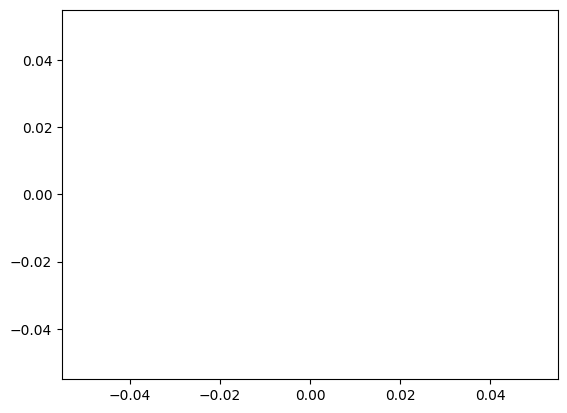

In [ ]:
plt.plot(res[-1][6000:6100], i1_out[6000:6100])

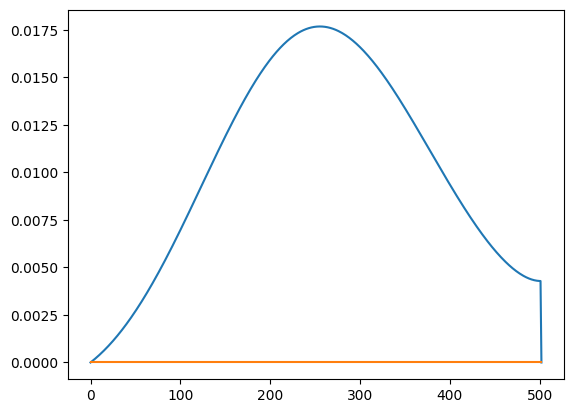

In [ ]:
plt.plot(res[0][71].T)

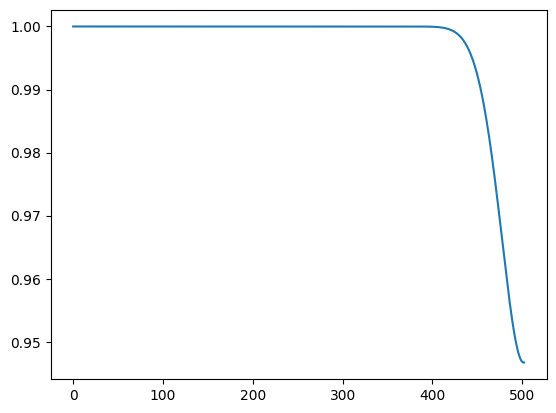

In [ ]:
plt.plot(res[1][70, :])

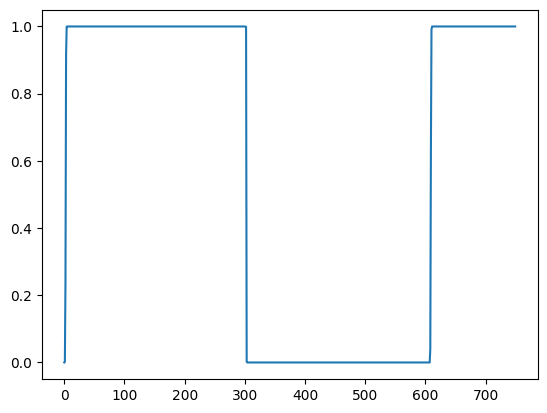

In [ ]:
plt.plot(res[1][:, 60])

In [ ]:
#i_out
#res[-1]
#res[0].shape
#mstep.model.reactor.D
#tma_n0, h2o_n0
plt.plot(np.mean(res[1][:, 31:37], axis=1))

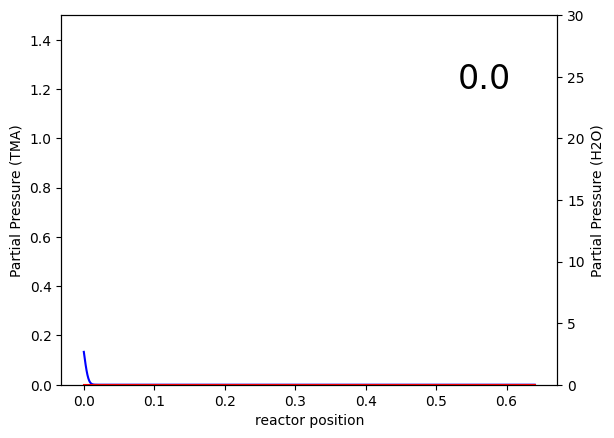

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
cutoff = -1#int(res[0][0,0,:].shape[0]/10)+1
fig = plt.gcf()
plt.ylim(0, 1.5)
line1 = plt.plot(mstep.model.setup.z, res[0][0,0,:cutoff], color='blue') #.shape
plt.xlabel('reactor position')
plt.ylabel('Partial Pressure (TMA)')
ax2 = plt.gca().twinx()
line2 = ax2.plot(mstep.model.setup.z, res[0][0,1,:cutoff], color='red') #.shape
plt.ylim(0, 30.0)

plt.ylabel('Partial Pressure (H2O)')
text1 = plt.annotate('0', xy=(0.8, 0.8), xycoords='axes fraction', fontsize=24)

def update(frame):
    # for each frame, update the data stored on each artist.
    #line1.set_xdata(t[:frame])
    line1[0].set_ydata(res[0][frame,0,:cutoff])
    line2[0].set_ydata(res[0][frame,1,:cutoff])
    text1.set_text(f'{res[-1][frame]:.1f}')
    return (line1, line2)


ani = animation.FuncAnimation(fig=fig, func=update, frames=res[0].shape[0], interval=30)
# plt.show()

In [ ]:
ani.save(filename="/content/sample_data/ffmpeg_example.mp4", writer="ffmpeg")

In [ ]:
res[0].shape #.shape

(750, 2, 503)

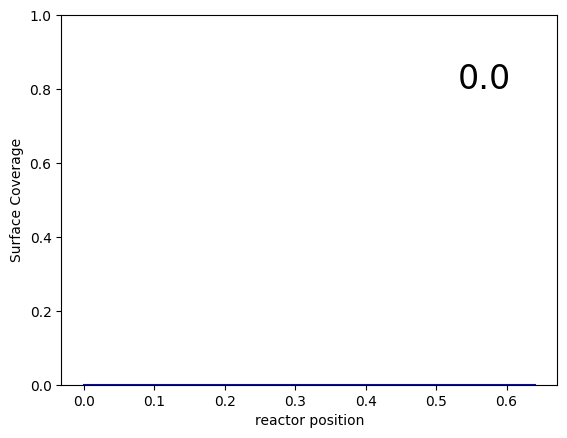

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
cutoff = -1#int(res[0][0,0,:].shape[0]/10)+1
fig = plt.gcf()
plt.ylim(0.0, 1.0)
line1 = plt.plot(mstep.model.setup.z, res[1][0,:cutoff], color='blue') #.shape
plt.xlabel('reactor position')
plt.ylabel('Surface Coverage')
# ax2 = plt.gca().twinx()
# line2 = ax2.plot(mstep.model.setup.z, res[0][0,1,:cutoff], color='red') #.shape
# plt.ylim(0, 30.0)

# plt.ylabel('Partial Pressure (H2O)')
text1 = plt.annotate('0', xy=(0.8, 0.8), xycoords='axes fraction', fontsize=24)

def update(frame):
    # for each frame, update the data stored on each artist.
    #line1.set_xdata(t[:frame])
    line1[0].set_ydata(res[1][frame,:cutoff])
    #line2[0].set_ydata(res[0][frame,1,:cutoff])
    text1.set_text(f'{res[-1][frame]:0.1f}')
    return (line1,)

#update(700)
ani = animation.FuncAnimation(fig=fig, func=update, frames=res[0].shape[0], interval=30)
ani.save(filename="/content/sample_data/coverage.mp4", writer="ffmpeg")
# plt.show()

In [ ]:
[res[0][i,0,1:cutoff].sum() for i in [0, 1, 2, 3, 4, 5, 10, 100, 300, 500, 700]]

[np.float64(2.8469555007915344),
 np.float64(4.458426649604003),
 np.float64(4.1462864359312075),
 np.float64(3.339198959356556),
 np.float64(2.959311040288755),
 np.float64(2.722007424514576),
 np.float64(2.186403950827578),
 np.float64(1.237127626983491),
 np.float64(0.07258660077967705),
 np.float64(0.002786195199230338),
 np.float64(1.4387251337221485)]

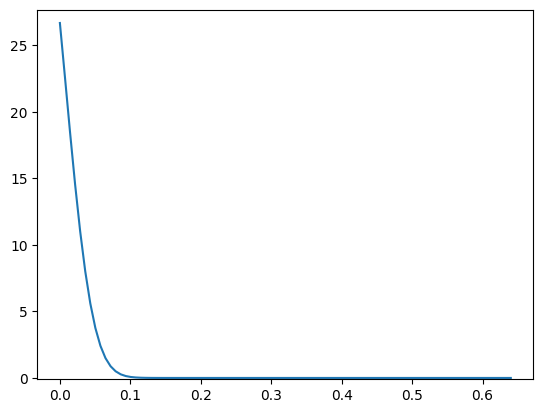

In [ ]:
import matplotlib.pyplot as plt

cutoff = -1#int(res[0][0,0,:].shape[0]/10)+1

plt.ylim(-.1, h2o_n0+1)
plt.plot(mstep.model.setup.z, res[0][310,1,:cutoff]) #.shape

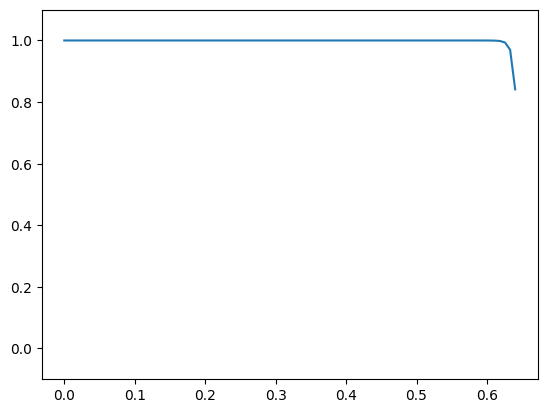

In [ ]:
plt.ylim(-.1, 1.1)
plt.plot(mstep.model.setup.z, res[1][270,:cutoff]) #.shape

In [ ]:
#res[0][-1, 0, -1]
dt = mstep.model.setup.tau[1] - mstep.model.setup.tau[0]
np.exp(-dt/0.22)

np.float64(0.9708085288907243)

# Coupled

## Imports

In [ ]:
import numpy as np
from scipy.constants import Boltzmann as kB
from scipy.constants import N_A, R
from scipy.integrate import solve_ivp
from scipy.sparse import lil_matrix
import torch
import torch.nn as nn

## Assist Functions

In [ ]:
def torr_to_pa(p_torr):
    return p_torr * 133.322

def axial_velocity(flow_sccm, p_torr, T, R):
    """Eq. (14): u = (p0 T phi) / (p T0 pi R^2), phi in sccm."""
    p0, T0 = 101325.0, 273.15          # standard conditions for sccm
    phi = flow_sccm * 1e-6 / 60.0      # sccm -> m^3/s at STP
    p = torr_to_pa(p_torr) #p_torr * 133.322
    return p0 * T * phi / (p * T0 * np.pi * R ** 2)

def adsorption_area(b_film=2.0, rho=3990.0, gpc=106e-12, M=101.96e-3):
    return M/(b_film * rho*gpc)

def particle_velocity(M, T):
    return np.sqrt(8*kB*T/(np.pi*M))

## Reaction definitions

In [ ]:
class Reactant:
    def __init__(self, vth, M):
        self.vth = vth
        self.M = M

    def diffusion_coefficient(self, M0, p, T):
        sigma, omega = 3.5, 0.5
        D = 3 / (8*np.sqrt(2*np.pi)) * (kB * T)**(3/2) * (1/self.M + 1/M0)**(1/2) / (p * (sigma * 1e-10)**2 * omega)
        self.D = D
        return self.D

class Reactor_1D:
    def __init__(self, Pe=None, D=None):


        self.x_rhs = {} #if Da is None else Da
        self.th_rhs = {} #if gamma is None else gamma

        self.D = {} if D is None else D
        self.reactants = {}

    def set_reactor_parameters(self, T, L, R, V=None):
        self.T = T
        self.L = L
        self.R = R
        self.V = V if V is not None else np.pi * R ** 2 * L

    def set_surface_parameters(self, S):
        #self.s0 = s0
        self.S = S

    def set_carrier_parameters(self, flow_sccm, M0, p=None, p_torr=None):
        self.flow_sccm = flow_sccm
        self.p = p if p is not None else torr_to_pa(p_torr)
        self.M0 = M0
        self.u = axial_velocity(self.flow_sccm, self.p, self.T, self.R)

    def set_reactant_parameters(self, id, vth, M, s0):
        self.reactants[id] = Reactant(vth, M)
        R_i = self.reactants[id]
        self.D[id] = R_i.diffusion_coefficient(self.M0, self.p, self.T)
        self.x_rhs[id] = (self.S/self.V)*(R_i.vth)/(4)
        self.th_rhs[id] = (s0*R_i.vth)/4

## Profile Setup

In [ ]:
class ReactorSetupProfile:

    def __init__(self, z=None, tau=None, x=None, theta=None):
        self.z = z
        self.tau = tau
        self.theta = {} if theta is None else theta
        self.x = {} if x is None else x

    def construct_time_profile(self, tau_end, D, dz=None, n_out=None):
        if n_out is None:
            if dz is None:
                if self.dz is None:
                    dz = 0.1
                    print('No dz found or provided.')
                else:
                    dz = self.dz
            dt = (0.2 * dz**2)/D
            t_steps = tau_end // dt
            self.dt = dt
            self.tau = dt * np.arange(0, int(t_steps) + 1)
        else:
            self.tau = np.linspace(0, tau_end, n_out)

    def construct_space_profile(self, z_max, u_D=None, n_z=None, min_z=100):
        #where u_D is u/D
        if n_z is None:
            d = 0.1/u_D
            n = int(np.ceil(z_max/d))
        else:
            n = int(n_z)
        z = np.linspace(0.0, z_max, n + 1)
        d = z[1] - z[0]

        self.z = z
        self.dz = d

    def initialize_theta(self, id, n=None, theta=None, initial_theta=0.0):
        if n is None:
            if self.z is None:
                raise ValueError("z not defined")
            else:
                n = len(self.z)
        elements = n+1 if INCLUSIVE_THETA else n-1
        if theta is None:
            self.theta[id] = np.full(elements, float(initial_theta))
        else:
            if n is not None:
                assert len(theta) == (elements)
            self.theta[id] = theta

    def initialize_x(self, id, n=None, x=None, initial_x=0.0):
        if n is None:
            if self.z is None:
                raise ValueError("xi not defined")
            else:
                n = len(self.z)

        if x is None:
            self.x[id] = np.full(n - 1, float(initial_x))
        else:
            if n is not None:
                assert len(x) == (n - 1)
            self.x[id] = x

    def flat_input_array(self):
        items = []
        for RC in self.x:
            items.append(self.x[RC])
        items.append(self.theta[0])
        return np.concatenate(items)

## Reactor Model

In [ ]:
INCLUSIVE_THETA = True
if INCLUSIVE_THETA:
    th_exc = lambda th, n: th[1:n]
    x_exc = lambda x, n: x
else:
    th_exc = lambda th, n: th
    x_exc = lambda x, n: x[1:n]

class ALD_Reactor_Model:
    def __init__(self,
                 T=200+273, L=45*1e-2, R=2.5*1e-2,
                 S=45*1e-2*2*np.pi*2.5*1e-2, V=None,
                 p_torr=1.0, flow_sccm=300, M0=28.0,
                 reactant_data={'TMA': {'M': 72.09, 'b_film': 2},
                                'H2O':{'M': 18.02, 'b_film': 3}},
                 z_max=10*45e-2, n_z=None, tau_end=0.2, tau_n=None,
                 inlet=None, outlet=None,
                 s0_func=lambda b: adsorption_area(b, rho=3990.0, gpc=106e-12, M=101.96e-3)):
        #self.ids = ids
        self.reactor = Reactor_1D()
        self.reactor.set_reactor_parameters(T=T, L=L, R=R, V=V)
        self.reactor.set_surface_parameters(S)
        self.reactor.set_carrier_parameters(p=torr_to_pa(p_torr), flow_sccm=flow_sccm,
                                            M0=M0 / N_A)

        self.Ds = []
        self.s0s = []
        self.vths = []
        self.x_rhs = []
        self.th_rhs = []

        for RC in reactant_data:
            r_data = reactant_data[RC]
            M = r_data['M'] / N_A
            vth = particle_velocity(M, T)
            self.reactor.set_reactant_parameters(RC, vth, M, s0=s0_func(r_data['b_film']))
            self.s0s.append(s0_func(r_data['b_film']))
            self.vths.append(vth)
            self.x_rhs.append(self.reactor.x_rhs[RC])
            self.th_rhs.append(self.reactor.th_rhs[RC])
            self.Ds.append(self.reactor.D[RC])

        self.x_rhs = np.array(self.x_rhs)[:, None]
        self.th_rhs = np.array(self.th_rhs)[:, None]
        self.Ds = np.array(self.Ds)[:, None]
        self.s0s = np.array(self.s0s)[:, None]
        self.vths = np.array(self.vths)[:, None]

        #Get reactor profiles
        # Spatial profile xi is normalized by L, but remember to multiply by L when displaying.
        # Cases where dz is used are scaled by L to account for us not using the 'normalized' coefficients
        self.setup = ReactorSetupProfile()
        self.setup.construct_space_profile(z_max, u_D = np.max(self.reactor.u/self.Ds), n_z=n_z, min_z=0)
        self.setup.construct_time_profile(tau_end=tau_end, D=np.max(self.Ds), dz=None, n_out=tau_n)

        #Make the profiles
        for RC in reactant_data:
            self.setup.initialize_x(RC, n=None, x=None, initial_x=0.0)
        self.setup.initialize_theta(0, n=None, theta=None, initial_theta=0.0)

        if inlet is None:
            self.inlet = lambda t: np.array([1.0, 0.0]).T
        else:
            self.inlet = inlet

        if outlet is None:
            self.outlet = lambda t: np.array([0.0, 0.0]).T
        else:
            self.outlet = outlet

        self.reset_internal_state()

    def reset_internal_state(self):
        self.y0 = self.setup.flat_input_array()
        self.old_inlet = np.zeros((2, 1), dtype='float')
        self.old_t = 0.0

    def run_model(self, outlet_type="dirichlet", epsilon=1.0,
                  rtol=1e-4, atol=1e-7, method="BDF",
                  betas = [0.001, 0.001],
                  perturbation = lambda x: x, t_offset=0, t_r = 0.22):
    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n

        n = len(self.setup.z)
        d = self.setup.dz # * self.reactor.L
        nx = n - 1

        co_adv = -self.reactor.u / (2.0 * d)
        co_lap = self.Ds / (d ** 2)

        tau_end = self.setup.tau[-1]
        inlet = self.inlet
        outlet= self.outlet

        def rhs(t, y):
            xi_x1 = y[:nx]
            xi_x2 = y[nx:2*nx]
            th = y[2*nx:]

            x1_full = np.empty(n + 1)
            x1_full[1:n] = xi_x1
            x2_full = np.empty(n + 1)
            x2_full[1:n] = xi_x2

            x_full = np.stack((x1_full, x2_full))


            I0, O0 = inlet(t+t_offset), outlet(t+t_offset)

            for i in range(len(x_full)):
                OI = self.old_inlet[i]
                if I0[i] is None:
                    x_full[i, 0] = OI * np.exp(-np.abs(dt/t_r)) #+ dt*0.5 * (co_lap[i] * 2 * (x_full[i, 1] - OI))
                else:
                    #x_full[i, 0] = I0[i]-(dt/0.1)*(I0[i] - OI)
                    x_full[i, 0] = I0[i] #inlet(t+t_offset)

                x_full[i, n] = x_full[i, n - 1] if outlet_type == "noflux" else O0[i]
            x_full = perturbation(x_full)
            co_diff = -np.stack((self.x_rhs[0] * betas[0] * (1-th_exc(th,n)),
                              self.x_rhs[1] * betas[1] * (th_exc(th,n))))


            lap = co_lap * (x_full[:, :-2] - 2.0 * x_full[:, 1:-1] + x_full[:, 2:])
            adv = co_adv * (x_full[:, 2:] - x_full[:, :-2])
            diff = co_diff * x_full[:, 1:n]

            dx = (lap + adv + diff)/epsilon

            dth = self.th_rhs[0] * betas[0] * (1-th) * x_exc(x_full[0], n) - \
                  self.th_rhs[1] * betas[1] * (th) * x_exc(x_full[1], n)

            res = np.concatenate((dx.ravel(), dth))

            self.old_inlet = x_full[:, 0]

            return res #np.concatenate((dx.ravel(), dth))

        dn_th = 1 if INCLUSIVE_THETA else -1
        boo_th = 1 if INCLUSIVE_THETA else 0
        jac_len = 2*nx + n + dn_th
        jac = lil_matrix((jac_len, jac_len), dtype=int)
        r = np.arange(nx)

        for c in range(2):
            jac[c*nx + r, c*nx + r] = 1
            jac[c*nx + r[:-1], c*nx + r[:-1] + 1] = 1
            jac[c*nx + r[1:], c*nx + r[1:] - 1] = 1

            jac[c*nx + r, 2*nx + boo_th + r] = 1              # x_i  <- theta_i
            jac[2*nx + boo_th + r, c*nx + r] = 1              # theta_i <- x_i
            if outlet_type == "noflux":
                jac[2*nx + n - 1 + dn_th, c*nx + nx - 1] = 1

        rt = np.arange(n + dn_th)
        jac[2*nx + rt, 2*nx + rt] = 1

        t_eval = self.setup.tau

        sol = solve_ivp(rhs, (0.0, tau_end), self.y0, method=method, t_eval=t_eval,
                        jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)

        if not sol.success:
            raise RuntimeError("integration failed: %s" % sol.message)

        #self.y0 = sol.y[:, -1]
        x = np.empty((sol.t.size, 2, n + 1))
        x[:, :, 0] = [inlet(t+t_offset) for t in sol.t]
        x[:, 0, 1:n] = sol.y[:nx].T
        x[:, 1, 1:n] = sol.y[nx:2*nx].T
        theta = sol.y[2*nx:].T

        if (np.sum(x[-1, 0, 1:n])/(n-2) < 0.01) and (x[-1, 0, 1:n].max() < 0.01):
            x[-1, 0, 1:n] = 0.0
        if (np.sum(x[-1, 1, 1:n])/(n-2) < 0.2) and (x[-1, 1, 1:n].max() < 0.2):
            x[-1, 1, 1:n] = 0.0
        if (np.sum(theta[-1])/(theta.shape[1]) < 0.01) and (theta[-1].min() < 0.01):
            theta[-1, :] = 0.0

        x[:, :, n] = x[:, :, n - 1] if outlet == "noflux" else [outlet(t+t_offset) for t in sol.t]
        x[x < 0] = 0

        self.y0 = np.concatenate((x[-1, :, 1:n].ravel(), theta[-1].ravel()))



        #np.clip(sol.y[2*nx:].T, 0.0, 1.0), causes instability
        #return ReactorProfile(self.setup.xi*self.reactor.L, sol.t, x, theta)
        return x[-1], theta[-1]


## Sample Models

### Flat Model

In [ ]:
class FlatModel(nn.Module):
    def __init__(self, s0, vth, dt, xpos, logbetas=[np.log(0.001), np.log(0.001)], initial_theta=0, device="cpu"):
        super().__init__()
        self.xpos = xpos #torch.tensor(xpos, device=device)
        self.device = device
        self.log_beta = nn.Parameter(torch.tensor(np.array(logbetas)))
        #self.log_beta = logbetas
        self.coeff = torch.tensor((1/4) * s0 * vth * dt, device=device)
        #(1/4) * s0 * vth * dt #torch.tensor((1/4) * s0 * vth * dt, device=device)
        self.initial_theta = torch.tensor(initial_theta, device=device)

    def get_betas(self):
        return np.exp(self.log_beta.cpu().numpy())

    def next_theta_deriv(self, x, last_theta):
        dtheta = (1-last_theta)*self.coeff * x[0] * torch.exp(self.log_beta[0]) - \
                 last_theta * self.coeff[1] * x[1] * torch.exp(self.log_beta[1])
        return last_theta + dtheta

    def next_theta(self, x, last_theta):
        dtheta = (1-last_theta) * (1-torch.exp(-self.coeff[0] * x[0] * torch.exp(self.log_beta[0])))
        dtheta -= last_theta * (1-torch.exp(-self.coeff[1] * x[1] * torch.exp(self.log_beta[1])))
        return last_theta + dtheta

    def get_theta_step(self, x_full):
        x = np.mean(x_full[:, self.xpos], axis=-1)
        x = torch.tensor(x, device=self.device)
        #initial_theta = torch.tensor(theta, device=self.device)
        next_theta = self.next_theta(x, self.initial_theta)
        self.initial_theta = next_theta
        return next_theta.numpy(force=True).copy()#, p

    def eval_step(self, x_full, gpc=106e-12):
        if x_full.ndim != 2:
            print('concentration profile has nonstandard dimensions, may not work as expected')
        with torch.no_grad():
            last_theta = self.initial_theta.numpy(force=True).copy()
            result = self.get_theta_step(x_full).item()
            return result
            #theta_change = np.abs(result - last_theta)
            #return theta_change * gpc
            #return result.cpu().numpy()
            #return result[0].cpu().numpy(), result[1].cpu().numpy()

### Channel Model

In [ ]:
class ChannelModel(nn.Module):
    def __init__(self, s0, vth, dt, xpos, W, H, T, L, carrier_pressure,
                 logbetas=[np.log(0.001), np.log(0.001)], device="cpu",
                 points = 50, reactants={'TMA': {'M': 72.09, 'd_r': 5.91e-10},
                                         'H2O':{'M': 18.02, 'd_r': 2.7e-10}},
                 carrier = {'M': 28.0, 'd_r': 3.64e-10}):
        super().__init__()
        self.W0 = W
        self.W = W
        self.H0 = H
        self.H = H
        self.xpos = xpos #torch.tensor(xpos, device=device)
        self.device = device
        self.log_beta = nn.Parameter(torch.tensor(np.array(logbetas)))
        #self.log_beta = logbetas
        self.dt = dt
        #self.coeff = torch.tensor((1/4) * s0 * vth * dt, device=device)
        #(1/4) * s0 * vth * dt #torch.tensor((1/4) * s0 * vth * dt, device=device)
        self.theta = self.initialize_profile(points, components=1) #torch.tensor(initial_theta, device=device)
        self.x = self.initialize_profile(points, components=2) #torch.tensor(initial_x, device=device)
        self.L = L
        self.dz = self.L/points
        self.T = T
        self.carrier_pressure = carrier_pressure
        self.za_funcs = []
        self.vths = vth
        self.s0s = s0

        for i, RC in enumerate(reactants):
            RI = reactants[RC]
            #Note that we want to use the !Molar Mass!, not the normalized molecular weight
            #Since the expressions use the gas constant and I don't want to work out where a N_A needs to be added
            self.za_funcs.append(lambda pA: self.calc_za(pA, self.carrier_pressure,
                                                         RI['M'], carrier['M'],
                                                         RI['d_r'], carrier['d_r']))

            #Function uses molecular & boltzmann
            #self.vths.append(particle_velocity(reactants[RC]['M']/N_A, T))

    def initialize_profile(self, points, components):
        return torch.zeros((components, points), device=self.device)

    def get_betas(self):
        return np.exp(self.log_beta.cpu().numpy())
    # -------------------------
    # Physics helpers
    # -------------------------
    def hydro_diameter(self):
        return 2 / (1/self.H + 1/self.W)

    def calc_za(self, pA, pB, MA, MB, da, db):
        term1 = (np.pi/4 * (da+db)**2 * \
                 np.sqrt(8*R*self.T/np.pi * (1/MA + 1/MB)) * pB)

        term2 = (np.pi * da**2 *
                 np.sqrt(16*R*self.T/(torch.pi*MA)) * pA)

        return (term1 + term2) / (R*self.T)

    def calc_Deff(self, va, za):
        #self.gas_velocity()
        #va = self.gas_velocity() #torch.sqrt(8*self.R*self.T/(torch.pi*self.MA))
        Da = 3*torch.pi/16 * va**2 / za

        h = self.hydro_diameter()
        #Dkn = h * torch.sqrt(8*self.R*self.T/(9*torch.pi*self.MA))
        Dkn = h * va / 3

        return 1 / (1/Da + 1/Dkn)

    def step(self, x0):

        h = self.hydro_diameter()
        #Deffs = []
        for i in range(2):
            za = self.za_funcs[i](x0[i])
            va = self.vths[i].item()
            Deff = self.calc_Deff(va, za)
            #Deffs.append(Deff)
            lap = (self.x[i, :-2] - 2.0 * self.x[i, 1:-1] + self.x[i, 2:])/self.dz**2

            #Yillami would also multiply by an extra kT, but he is using partial pressure
            #Should be right, since we are using x, which converts from p by a factor of kT
            g = 1/4 * va * self.x[i, 1:-1] * torch.exp(self.log_beta[i]) * (1-self.theta[0, 1:-1])
            dep = 4/h * g
            self.x[i, 1:-1] = self.x[i, 1:-1] + self.dt * (Deff*lap/(kB*self.T) - dep)
            self.x[i,0] = x0[i]
            self.x[i,-1] = self.x[i,-2]
            self.theta[0, 1:-1] = g * self.s0s[i].item()
            self.theta[0,0] = self.theta[0,1]
            self.theta[0,-1] = self.theta[0,-2]

        return self.x, self.theta

    # -------------------------
    # Forward simulation
    # -------------------------
    def forward(self, x_full, steps, gpc):
        x0 = np.mean(x_full[:, self.xpos], axis=-1)
        x0 = torch.tensor(x0, device=self.device)

        theta_history = [self.theta.numpy(force=True).copy()]

        for _ in range(steps):
            x, theta = self.step(x0)
            theta = theta.numpy(force=True).copy()
            entry_theta_change = np.abs(theta[0,0] - theta_history[-1][0,0])
            # update geometry (still differentiable)
            self.H = np.clip(self.H - entry_theta_change*gpc, min=1e-12)
            theta_history.append(theta)

        return np.stack(theta_history)

    def eval_step(self, x_full, gpc=106e-12, steps=1):
        if x_full.ndim != 2:
            print('concentration profile has nonstandard dimensions, may not work as expected')
        with torch.no_grad():
            result = self.forward(x_full, steps=steps, gpc=gpc)
            theta_change = np.abs(result[1:] - result[:-1])
            return theta_change.sum(axis=1) * gpc
            #return result.cpu().numpy(
            #return result
            #return result[0].cpu().numpy(), result[1].cpu().numpy()

## Coupled Models

In [ ]:
tma_n0 = torr_to_pa(150e-3)
h2o_n0 = torr_to_pa(80e-3)

#print(tma_n0/(R*373),  h2o_n0/(R*373))

OFF_STATE = 0

class ModelCoupling:
    def __init__(self, model=None, t_step=0.005,
                 recipe = [{'t': 0.1, 'p': [tma_n0, OFF_STATE]},
                            {'t': 60, 'p': [OFF_STATE, OFF_STATE]},
                            {'t': 1.0, 'p': [OFF_STATE, h2o_n0]},
                            {'t': 60, 'p': [OFF_STATE, OFF_STATE]}],
                 **kwargs):

        self.t_step = t_step

        if model is None:
            self.model_init(t_step=t_step, **kwargs)
        else:
            self.model = model
        self.coupling_init()

        #self.sample_model_init()
        self.set_recipe(recipe)

    def set_recipe(self, recipe, t_r=0.02):
        #recipe.t/2 > t_r > t_step
        #Assumes the padding offstate pressure is also the case for the last state pressure
        self.recipe = recipe
        self.cycle_time = np.sum([stage['t'] for stage in recipe])

        conc = np.zeros((round((self.cycle_time) / self.t_step)+1, 2), dtype='float')
        cstate = np.array([0, 0])[...,None].T
        ct = 0 #pad
        edge_length = round(t_r/self.t_step)
        interp = np.linspace(0, 1, edge_length)[...,None]

        for stage in recipe:
            #conc.append(stage['p']*int(stage['t']//t_step+1))
            center_point = round(ct/self.t_step)
            stage_p = np.array(stage['p'])[...,None].T
            #print(cstate, stage_p)
            #conc[center_point-edge_length:center_point+edge_length+1, :] = interp*stage_p + (1-interp)*cstate
            conc[center_point:center_point+edge_length, :] = interp*stage_p + (1-interp)*cstate
            conc[center_point+edge_length:,:] = stage_p
            cstate = stage_p
            ct += stage['t']

        #Clamp off relevant conc section
        start_index = np.argmax(np.sum(conc != 0, axis=1)!=0)
        #print(start_index + round(self.cycle_time/self.t_step))
        conc = conc[start_index-1: start_index + round(self.cycle_time/self.t_step), :]
        conc = conc #/(R*self.model.reactor.T) #pressure to concentration conversion
        self.conc = conc

    def model_init(self, t_step, T=373,
                   z_max=64*1e-2, L = 64*1e-2,
                   R = 1.75*1e-2, S=64*1e-2*2*np.pi*R,
                   p_torr=1.0, flow_sccm=120, M0=28.0,
                   n_z = 501, tau_n = 2,
                   reactant_data = {'TMA': {'M': 72.09, 'b_film': 2},
                                    'H2O': {'M': 18.02, 'b_film': 3}}):

        self.model = ALD_Reactor_Model(T=T, L=L, R=R, S=S,
                                        p_torr=p_torr, flow_sccm=flow_sccm, M0=M0,
                                        reactant_data=reactant_data,
                                        z_max=z_max, n_z=n_z,
                                        tau_end=t_step, tau_n=tau_n,
                                        inlet=self.I_by_time, outlet=None)

    def coupling_init(self, position_range = (31*1e-2, 35*1e-2)):
        z = self.model.setup.z #* self.model.reactor.L
        zpos = np.where(np.logical_and(z>=position_range[0], z<=position_range[1]))[0]
        self.flat_model = FlatModel(s0 = self.model.s0s,
                                    vth = self.model.vths,
                                    dt = self.t_step,
                                    xpos = zpos)

        self.har_model = ChannelModel(s0 = self.model.s0s,
                                      vth = self.model.vths,
                                      dt = self.t_step, #If smaller than t_step, must increase number of steps used in the running stage
                                      xpos = zpos,
                                      W=0.1e-3, H=0.2e-6, T=self.model.reactor.T,
                                      L = 200e-6,
                                      carrier_pressure=self.model.reactor.p,
                                      points=100)


    def I_by_time(self, t):
        t_ = t % self.cycle_time
        return self.conc[round(t_/self.t_step)]

    def run_model(self, time, log_freq=10, gpc=1):
        x_log = []
        theta_log = []
        betatheta_log = []
        tau_log = []

        tau_end = self.t_step #self.model.setup.tau[-1]
        #perturbation = self.sample_model.get_perturbation if use_perturbation else lambda x: x
        perturbation = lambda x: x #Not currently in use
        thick_log = []

        delta_channel_log = []
        sample_theta_log = []
        delta_theta_sum = 0
        last_theta = 0

        for i in range(int(time//tau_end)+1):
            t = i * tau_end

            x, theta = self.model.run_model(betas = [0.000, 0.000],
                                            perturbation = perturbation,
                                            t_offset=t, outlet_type='noflux', #outlet_type='derichlet',
                                            method = 'RK45')


            #Change gpc to 1 to
            sample_theta = self.flat_model.eval_step(x, gpc=gpc)
            #delta_channel = self.har_model(x, gpc=106e-12, steps=1) #keep steps=1 if dt = t_steps
            delta_theta_sum += gpc*np.abs(sample_theta-last_theta)
            last_theta = sample_theta

            if i % log_freq == 0:
                #delta_channel_log.append(delta_channel)
                x_log.append(x)
                theta_log.append(theta)
                tau_log.append(t)
                sample_theta_log.append(sample_theta)
                thick_log.append(delta_theta_sum)

        #np.array(delta_channel_log),
        return np.array(x_log), np.array(theta_log), np.array(thick_log), np.array(sample_theta_log), np.array(tau_log)

## Run Model

In [ ]:
mstep = ModelCoupling()

In [ ]:
tma_n0, tma_n0/(R*373), tma_n0/(kB*373)

(19.9983, 0.00644837168324651, 3.8833001949308613e+21)

In [ ]:
kB

1.380649e-23

In [ ]:
#mstep.model.#
test_prof = np.zeros((2,503))
test_prof[0,:] = 1e-5

In [ ]:
mstep.flat_model.eval_step(test_prof)

0.00020499061168839986

In [ ]:
mstep.conc[:,1].min()

np.float64(0.0)

[]

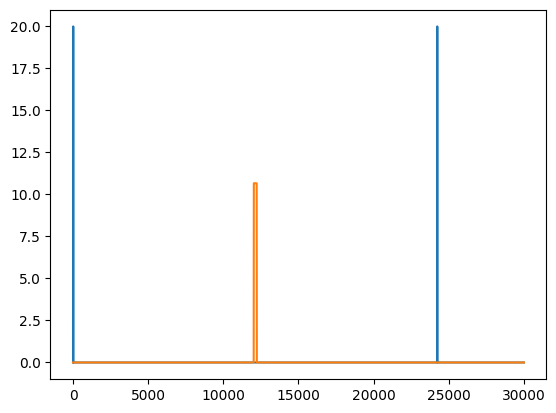

In [ ]:
i1_out = [mstep.I_by_time(t*0.005)[0] if mstep.I_by_time(t)[0] != None else 0 for t in range(int(150//0.005)+1)]
i2_out = [mstep.I_by_time(t*0.005)[1] if mstep.I_by_time(t)[1] != None else 0 for t in range(int(150//0.005)+1)]
#o_out = [mstep.O_by_time(t) for t in res[-1]]
plt.plot(i1_out)
plt.plot(i2_out)

#plt.plot(res[-1], o_out)
plt.plot()

In [ ]:
res = mstep.run_model(130)

/usr/local/lib/python3.13/dist-packages/scipy/integrate/_ivp/ivp.py:621: UserWarning: The following arguments have no effect for a chosen solver: `jac_sparsity`.
  solver = method(fun, t0, y0, tf, vectorized=vectorized, **options)


In [ ]:
#mstep.t_step
#res[1][:].max()
#res[-1]
#res[1][:,200].max()
res[0].min()

np.float64(-9.520407407036571e-08)

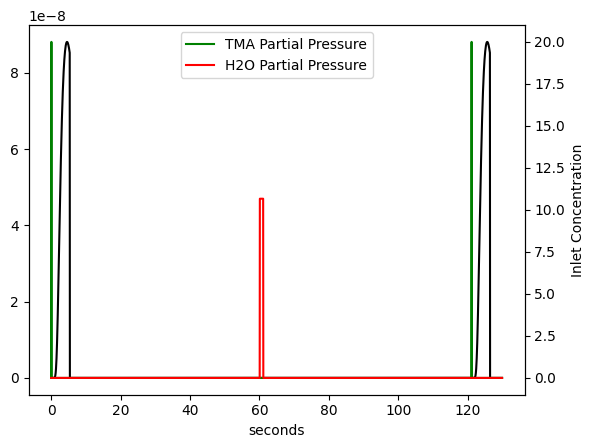

In [ ]:
from matplotlib import cm
import matplotlib.pyplot as plt

plt.plot(res[-1], res[0][:,0, -250], color='black')

#plt.ylim(0, 1)
#plt.ylabel('Thickness')
plt.xlabel('seconds')

plt.twinx()

i1_out = [mstep.I_by_time(t)[0] if mstep.I_by_time(t)[0] != None else 0 for t in res[-1]]
i2_out = [mstep.I_by_time(t)[1] if mstep.I_by_time(t)[1] != None else 0 for t in res[-1]]
#o_out = [mstep.O_by_time(t) for t in res[-1]]
plt.plot(res[-1], i1_out, color='green', label='TMA Partial Pressure')
plt.plot(res[-1], i2_out, color='red', label='H2O Partial Pressure')

plt.ylabel('Inlet Concentration')
plt.legend()
#plt.plot(res[-1], o_out)

In [ ]:
#plt.scatter(np.arange(len(res[2]))[::5]*mstep.t_step, res[2][::5])


[]

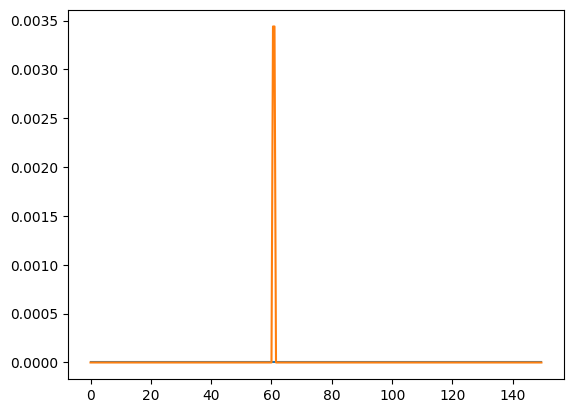

In [ ]:
i1_out = [mstep.I_by_time(t)[0] if mstep.I_by_time(t)[0] != None else 0 for t in res[-1]]
i2_out = [mstep.I_by_time(t)[1] if mstep.I_by_time(t)[1] != None else 0 for t in res[-1]]
#o_out = [mstep.O_by_time(t) for t in res[-1]]
plt.plot(res[-1], i1_out)
plt.plot(res[-1], i2_out)

#plt.plot(res[-1], o_out)
plt.plot()

In [ ]:
QCM = np.loadtxt('/content/sample_data/20260729-21;41;12 QCM.txt')
plt.plot(QCM[32000:40000,0], QCM[32000:40000,1])

FileNotFoundError: /content/sample_data/20260729-21;41;12 QCM.txt not found.

In [ ]:
QCM[4]-QCM[3]

array([0.102, 0.   ])

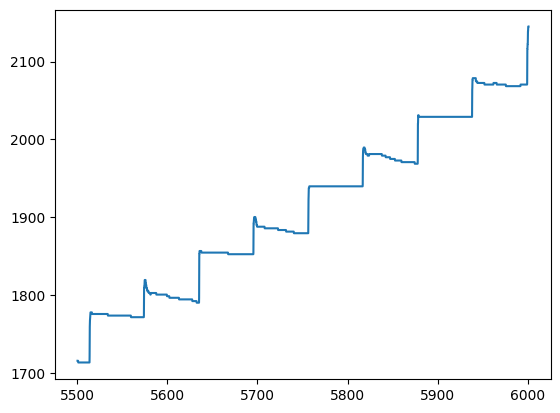

In [ ]:
A = 55000
A_d = 5000
start, end = A, A+A_d
plt.plot(QCM[start:end,0], QCM[start:end,1])
#plt.plot((QCM[start+1:end,1]-QCM[start:end-1,1])/(QCM[start+1:end,0]-QCM[start:end-1,0]))

In [ ]:
QCM[:,0].max()#/12423

np.float64(43304.1)

In [ ]:
#12423/3600

# Misc

Text(0, 0.5, 'Inlet Concentration n/$n_0$')

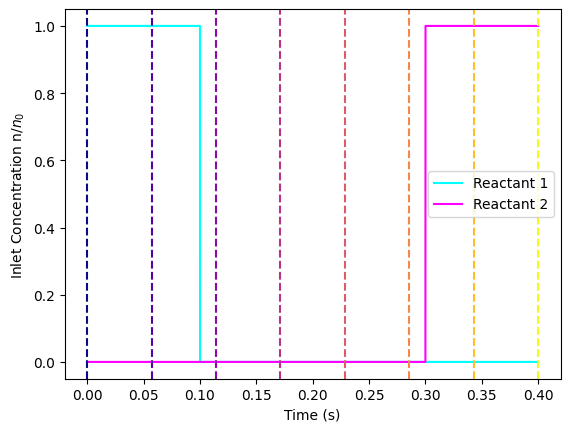

In [ ]:
ccnt = res.tau.shape[0]//10000
cmap_spaced = plt.get_cmap('plasma', ccnt)
print(cmap_spaced(np.linspace(0, 1, ccnt)))

accum = []
for t in res.tau:
    ns = custom_inlet(t)
    accum.append(ns)
accum = np.array(accum)
#plt.scatter(res.tau, accum[:, 0], c= cmap_spaced(np.linspace(0,1,len(accum))), cmap='plasma', marker='X')
#plt.scatter(res.tau, accum[:, 1], c= cmap_spaced(np.linspace(0,1,len(accum))), cmap='plasma', marker='s')
plt.plot(res.tau, accum[:, 0], color='cyan', label='Reactant 1')
plt.plot(res.tau, accum[:, 1], color='magenta', label='Reactant 2')

for v in np.linspace(0, 1, ccnt):
    plt.axvline(v*0.4, color=cmap_spaced(v), linestyle='--')

plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('Inlet Concentration n/$n_0$')

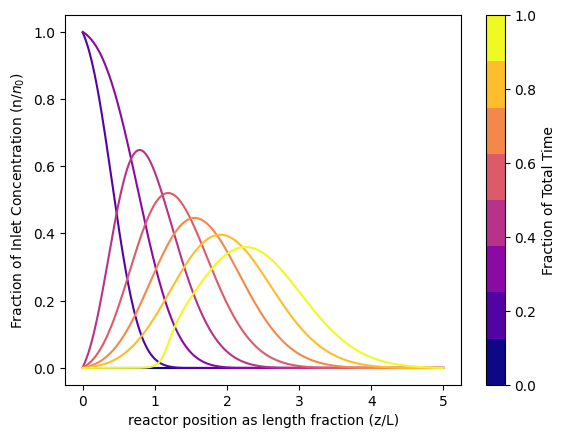

In [ ]:
#test_model.reactor.reactants['TMA'].vth
from matplotlib import cm
import matplotlib.pyplot as plt
xpos = res.xi
for i in range(0, res.x.shape[0], 10000):
    plt.plot(xpos, res.x[i,0,1:], color=cmap_spaced(i/res.tau.shape[0]))

plt.xlabel('reactor position as length fraction (z/L)')
plt.ylabel('Fraction of Inlet Concentration (n/$n_0$)')
mappable = cm.ScalarMappable(cmap=cmap_spaced)
plt.gcf().colorbar(mappable, ax=plt.gca(), label='Fraction of Total Time')

In [ ]:
# mappable = cm.ScalarMappable(cmap=cmap_spaced)
# plt.gcf().colorbar(mappable, ax=plt.gca())

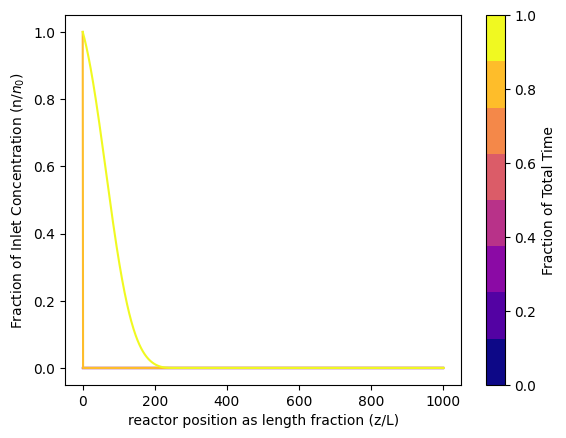

In [ ]:
#test_model.reactor.reactants['TMA'].vth
import matplotlib.pyplot as plt
for i in range(0, res.x.shape[0], 10000):
    plt.plot(res.x[i,1,:], color=cmap_spaced(i/res.tau.shape[0]))

plt.xlabel('reactor position as length fraction (z/L)')
plt.ylabel('Fraction of Inlet Concentration (n/$n_0$)')
mappable = cm.ScalarMappable(cmap=cmap_spaced)
plt.gcf().colorbar(mappable, ax=plt.gca(), label='Fraction of Total Time')

Text(0, 0.5, 'Fraction of Inlet Concentration (n/$n_0$)')

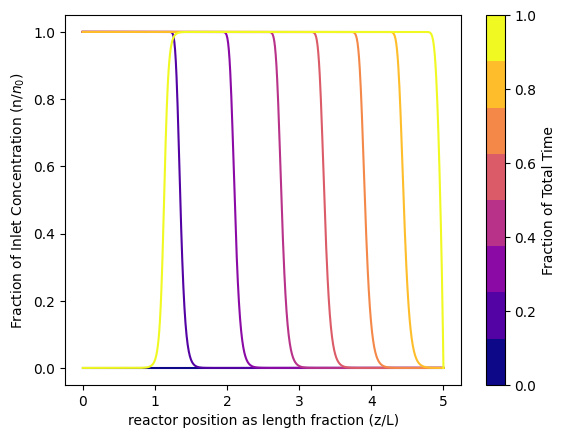

In [ ]:
for i in range(0, res.theta.shape[0], 10000):
    plt.plot(xpos, res.theta[i,1:], color=cmap_spaced(i/res.tau.shape[0]))

plt.gcf().colorbar(mappable, ax=plt.gca(), label='Fraction of Total Time')

plt.xlabel('reactor position as length fraction (z/L)')
plt.ylabel('Fraction of Inlet Concentration (n/$n_0$)')

In [ ]:
# test_model = ALD_Reactor_Model()
# res = test_model.run_model()
import numpy as np

QCM = np.loadtxt('/content/sample_data/20260729-21;41;12 QCM.txt')

In [ ]:
QCM[:, 1].argmin()

np.int64(31936)

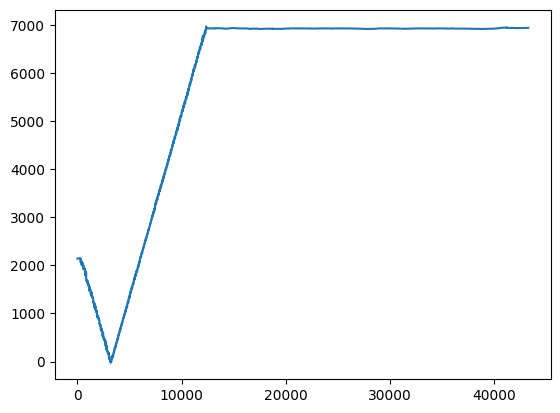

In [ ]:
import matplotlib.pyplot as plt
plt.plot(QCM[:,0], QCM[:,1])
#

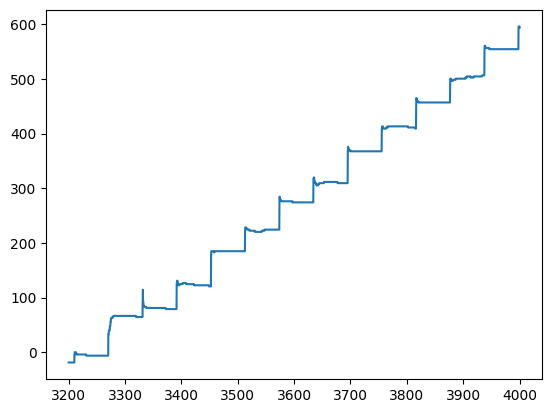

In [ ]:
plt.plot(QCM[32000:40000,0], QCM[32000:40000,1])

In [ ]:
# T = test_model.reactor.T

# 3 / (8*np.sqrt(2*np.pi)) * (kB * T)**(3/2) * (1/1e-22 + 1/5e-23)**(1/2) / (133.322 * (3.5 * 1e-10)**2 * 0.5)

In [ ]:
#res.tau

In [ ]:
# #test_model.reactor.reactants['TMA'].vth
# import matplotlib.pyplot as plt
# for i in range(0, res.x.shape[0], 500):
#     plt.plot(res.x[i,0,:])

In [ ]:
# for i in range(0, res.theta.shape[0], 500):
#     plt.plot(res.theta[i,:])

In [ ]:
# which ontology model this code implements (ontology/core.yaml `models:`)
MODEL_ID = "yanguas_gil_elam_tubular_reactor"

# Table caption / Sec. IV A: TMA/H2O in the Argonne viscous-flow reactor
PAPER_TMA = dict(Pe=65.0, Da=1550.0, gamma=2.5)

def inlet_program(t_end, t_dose=None, t_purge=None):
    if t_dose is None:
        inlet = lambda t: 1.0
    else:
        def inlet(t):
            if (t % (t_dose + t_purge)) < t_dose:
                return 1.0
            else:
                return 0.0

    return inlet

class ReactorProfile:
    """Result of :func:`solve`.

    xi    : (n_xi,)          normalised axial position z/L
    tau   : (n_t,)           normalised time t D / L^2
    x     : (n_t, n_xi)      normalised precursor density n/n_0
    theta : (n_t, n_xi)      fraction of AVAILABLE sites (paper convention)
    """

    def __init__(self, xi, tau, x, theta):
        self.xi = xi
        self.tau = tau
        self.x = x
        self.theta = theta

    @property
    def coverage(self):
        """Fraction of sites CONSUMED, i.e. the nc_infill_model convention and
        the quantity proportional to deposited thickness."""
        return 1.0 - self.theta

    def growth_profile(self, index=-1):
        """Relative film thickness along the reactor: 1 - theta."""
        return 1.0 - self.theta[index]


def solve(Pe, Da, gamma, tau_end, tau_dose=None, xi_max=10.0, n_xi=None,
          epsilon=1.0, outlet="dirichlet", theta_init=1.0, x_init=0.0,
          n_out=120, rtol=1e-7, atol=1e-10, tau_purge=None):
    """Integrate Eqs. (9)-(10).

    Parameters
    ----------
    Pe, Da, gamma : float
        The three dimensionless groups, Eqs. (11)-(13).
    tau_end : float
        Normalised end time.
    tau_dose : float, optional
        Square-pulse length; the inlet drops to 0 afterwards.  None = dose for
        the whole run.
    xi_max : float
        Domain length in units of L.  The paper uses 10 to approximate the
        semi-infinite reactor.
    epsilon : float
        Coefficient on the accumulation term dx/dtau.  1.0 reproduces the
        published equation (an open tube); < 1 represents the void fraction of
        a porous medium.
    outlet : {"dirichlet", "noflux"}
        "dirichlet" is the paper's x(xi_max, tau) = 0 open outlet; "noflux"
        closes the far end, as for a blind feature or a film on a substrate.
    theta_init, x_init : scalar | array | callable
        Initial conditions; the paper uses theta = 1, x = 0.

    Returns
    -------
    ReactorProfile
    """
    # the paper's criterion for the central-difference scheme (Sec. III):
    # Pe*dxi < 0.1, which bounds the cell Peclet number and keeps the scheme
    # free of the oscillations central differencing shows on advection.
    if n_xi is None:
        n_xi = max(1000, int(np.ceil(Pe * xi_max / 0.09)))
    n = int(n_xi)
    xi = np.linspace(0.0, xi_max, n + 1)
    d = xi[1] - xi[0]
    if Pe * d > 0.1:
        raise ValueError("Pe*dxi = %.3g > 0.1; increase n_xi to at least %d"
                         % (Pe * d, int(np.ceil(Pe * xi_max / 0.1))))

    def prof(v, default):
        if v is None:
            return np.full(n + 1, float(default))
        if callable(v):
            return np.asarray(v(xi), dtype=float) * np.ones(n + 1)
        a = np.asarray(v, dtype=float)
        return np.full(n + 1, float(a)) if a.ndim == 0 else a.copy()

    inlet = inlet_program(tau_end, tau_dose, tau_purge)

    # unknowns: x_1..x_{n-1} (interior), theta_0..theta_n
    nx = n - 1
    inv_d2 = 1.0 / d ** 2
    half_pe = Pe / (2.0 * d)

    def rhs(t, y):
        xi_x1 = y[:nx]
        xi_x2 = y[nx:2*nx]
        th = y[2*nx:]
        th = np.clip(th, 0.0, 1.0)

        x1_full = np.empty(n + 1)
        x1_full[0] = inlet(t)
        x1_full[1:n] = xi_x1
        x1_full[n] = x1_full[n - 1] if outlet == "noflux" else 0.0

        x2_full = np.empty(n + 1)
        x2_full[0] = 0 #1.0 - inlet(t)
        x2_full[1:n] = xi_x2
        x2_full[n] = x2_full[n - 1] if outlet == "noflux" else 0.0

        x_full = np.stack((x1_full, x2_full))

        lap = (x_full[:, :-2] - 2.0 * x_full[:, 1:-1] + x_full[:, 2:]) * inv_d2
        adv = -half_pe * (x_full[:, 2:] - x_full[:, :-2])
        diff = -np.stack((Da * (1-th[1:n]), Da * (th[1:n])))
        dx = ((lap + adv + (diff * x_full[:, 1:n])) / epsilon)
        dth = gamma * Da * (1-th) * x_full[0] - gamma * Da * (th) * x_full[1]
        return np.concatenate((dx.ravel(), dth))

    jac = lil_matrix((2*nx + n + 1, 2*nx + n + 1), dtype=int)
    r = np.arange(nx)

    for c in range(2):
        jac[c*nx + r, c*nx + r] = 1
        jac[c*nx + r[:-1], c*nx + r[:-1] + 1] = 1
        jac[c*nx + r[1:], c*nx + r[1:] - 1] = 1

        jac[c*nx + r, 2*nx + 1 + r] = 1              # x_i  <- theta_i
        jac[2*nx + 1 + r, c*nx + r] = 1              # theta_i <- x_i
        if outlet == "noflux":
            jac[2*nx + n, c*nx + nx -1] = 1

    rt = np.arange(n + 1)
    jac[2*nx + rt, 2*nx + rt] = 1

    y0 = np.concatenate((prof(x_init, 0.0)[1:n], prof(x_init, 0.0)[1:n], prof(theta_init, 0.0)))
    t_eval = np.linspace(0.0, tau_end, n_out)
    sol = solve_ivp(rhs, (0.0, tau_end), y0, method="BDF", t_eval=t_eval,
                    jac_sparsity=jac.tocsr(), rtol=rtol, atol=atol)
    if not sol.success:
        raise RuntimeError("integration failed: %s" % sol.message)

    x = np.empty((sol.t.size, 2, n + 1))
    x[:, 0, 0] = [inlet(t) for t in sol.t]
    x[:, 1, 0] = [1-inlet(t) for t in sol.t]
    x[:, 0, 1:n] = sol.y[:nx].T
    x[:, 1, 1:n] = sol.y[nx:2*nx].T
    x[:, :, n] = x[:, :, n - 1] if outlet == "noflux" else 0.0
    theta = np.clip(sol.y[2*nx:].T, 0.0, 1.0)
    return ReactorProfile(xi, sol.t, x, theta)


